# Proyecto final integrador — Big Data

**Analítica de datos a gran escala y benchmarking experimental: Pandas vs. PySpark sobre US Accidents (2016–2023)**

Maestría en Inteligencia Artificial, Universidad de Palermo — **Grupo 3**: Fernando Romero Etchenique, Aldo Sebastián López, Carlos Johansen.

Consultas asignadas: **C4** (hotspots, común a todos), **C1** (distribución horaria), **C5** (distancia y duración),
**C9** (intersecciones por texto) y **C10** (despeje según luz y tipo de día).

| Sección | Contenido |
|---|---|
| 0 a 5 | Configuración, entorno, descarga, sesión de Spark y funciones de carga |
| 6 | Validación y perfil del dataset |
| 7 | Funciones de medición |
| 8 | Las cinco consultas sobre el CSV original, cada una en Spark y en Pandas |
| 9 | Segundo escenario: las mismas consultas sobre el dataset convertido a Parquet |
| 10 | Tablas de benchmarking y Speedup de los dos escenarios |
| 11 | Memoria en Pandas |
| 12 | Descarga de resultados |
| 13 | Experimento opcional: carga completa en Pandas |
| 14 | Consigna 6: clasificación supervisada con Spark MLlib |

**Cómo ejecutarlo.**

- **PC local (entorno en el que se obtuvieron los resultados):** tener Java 17 o superior, dejar
  `US_Accidents_March23.csv` en la misma carpeta que este notebook (o indicar su ruta en `RUTA_CSV_MANUAL`)
  y ejecutar todas las celdas.
- **Google Colab:** cargar el secreto `KAGGLE_API_TOKEN` (ícono de la llave) y elegir
  *Entorno de ejecución → Ejecutar todo*. La versión final no se probó en Colab: con su memoria y sus
  núcleos, el modelo de la sección 14 puede tardar mucho o no completarse.

## 0. Configuración

In [1]:
# ----- Datos -----
# Ruta al CSV si ya está descargado (PC local). En Colab dejar en None.
# Ejemplo: RUTA_CSV_MANUAL = r"C:\datos\us_accidents\US_Accidents_March23.csv"
RUTA_CSV_MANUAL = None
FILAS_ESPERADAS = 7_728_394      # filas que informa el enunciado; valida la carga

# ----- Spark -----
MEMORIA_SPARK = None             # por ejemplo "8g"; None = la mitad de la RAM

# ----- Benchmarking -----
REPETICIONES = 3                 # 1 para una corrida de verificación; 3 para la medición final

# ----- C1: filtro temporal (ambos extremos incluidos) -----
C1_DESDE, C1_HASTA = "2021-01-01", "2022-12-31"
C1_HORAS_PICO = 3                # cuántas horas se informan como pico

# ----- C4: hotspots -----
C4_RADIO_KM = 2.0                # radio de influencia R
C4_ESTADO = None                 # None = todo el país; o un estado, por ejemplo "CA"
C4_CRITERIO = "graves"           # "graves" | "densidad" | "ponderado"
C4_PESOS = {1: 1, 2: 2, 3: 4, 4: 8}   # pesos por severidad del criterio "ponderado"
C4_TOP = 5
C4_CANDIDATOS = 300              # celdas candidatas que se evalúan con distancia exacta
C4_CANDIDATOS_MAX = 20_000       # tope si hay que ampliar el conjunto de candidatas
C4_SEPARACION_KM = 2 * C4_RADIO_KM    # distancia mínima entre dos hotspots informados

# ----- Duraciones (C5 y C10) -----
DURACION_MAX_DIAS = 7            # la "media acotada" excluye duraciones negativas o mayores a este valor

# ----- Segundo escenario: Parquet -----
ESCENARIO_PARQUET = True         # convierte el CSV a Parquet y repite las consultas sobre ese formato
RUTA_PARQUET = None              # None = us_accidents.parquet en la carpeta de trabajo

# ----- Salidas -----
DESCARGAR_ZIP = True             # en Colab, descarga resultados y figuras al terminar
INTENTAR_CARGA_COMPLETA_PANDAS = False   # experimento de la sección 13

## 1. Java y librerías

Spark corre sobre la máquina virtual de Java (versión 17 o superior para Spark 4).
En Colab se instala Java 17 con `apt`; en una PC local tiene que estar instalado de antemano.

In [2]:
import os, sys, subprocess, shutil, importlib.util

EN_COLAB = "google.colab" in sys.modules

def _pip(*paquetes):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *paquetes], check=False)

if EN_COLAB:
    subprocess.run("apt-get install -y -qq openjdk-17-jdk-headless", shell=True,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    _java_home = "/usr/lib/jvm/java-17-openjdk-amd64"
    if os.path.isdir(_java_home):
        os.environ["JAVA_HOME"] = _java_home
        os.environ["PATH"] = _java_home + "/bin:" + os.environ["PATH"]
    _pip("-U", "kagglehub")

for _paquete in ["pyspark", "pandas", "numpy", "psutil", "kagglehub", "matplotlib", "pyarrow"]:
    if importlib.util.find_spec(_paquete) is None:
        _pip(_paquete)

def version_java():
    exe = shutil.which("java")
    if os.environ.get("JAVA_HOME"):
        candidato = os.path.join(os.environ["JAVA_HOME"], "bin", "java")
        exe = shutil.which(candidato) or exe
    if exe is None:
        return None
    salida = subprocess.run([exe, "-version"], capture_output=True, text=True)
    lineas = [l for l in (salida.stderr + salida.stdout).splitlines() if "version" in l.lower()]
    return lineas[0].strip() if lineas else None

JAVA = version_java()
if JAVA is None:
    raise RuntimeError("No se encontró Java. Spark necesita Java 17 o superior instalado "
                       "(o la variable JAVA_HOME apuntando a un JDK).")
print("Java:", JAVA)

Java: java version "21.0.9" 2025-10-21 LTS


## 2. Registro del entorno de cómputo

Modelo de CPU, núcleos físicos y lógicos, RAM, sistema operativo y versiones, como pide el enunciado.

In [3]:
import json, platform, time, gc, math, re, csv, glob, threading, datetime
import numpy as np, pandas as pd, psutil, pyspark

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

def modelo_cpu():
    try:
        so = platform.system()
        if so == "Linux":
            with open("/proc/cpuinfo") as f:
                for linea in f:
                    if linea.lower().startswith("model name"):
                        return linea.split(":", 1)[1].strip()
        elif so == "Windows":
            r = subprocess.run(["powershell", "-NoProfile", "-Command",
                                "(Get-CimInstance Win32_Processor).Name"],
                               capture_output=True, text=True)
            if r.stdout.strip():
                return r.stdout.strip()
        elif so == "Darwin":
            r = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                               capture_output=True, text=True)
            if r.stdout.strip():
                return r.stdout.strip()
    except Exception:
        pass
    return platform.processor() or "desconocido"

RAM_TOTAL_GB = psutil.virtual_memory().total / 2**30

ENTORNO = {
    "Plataforma": "Google Colab" if EN_COLAB else "PC local",
    "CPU": modelo_cpu(),
    "Núcleos físicos": psutil.cpu_count(logical=False),
    "Núcleos lógicos": psutil.cpu_count(logical=True),
    "RAM instalada (GB)": round(RAM_TOTAL_GB, 1),
    "Sistema operativo": platform.platform(),
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "PySpark": pyspark.__version__,
    "Java": JAVA,
}
pd.DataFrame({"Valor": ENTORNO})

,Valor
Plataforma,PC local
CPU,Intel(R) Core(TM) i9-10980HK CPU @ 2.40GHz
Núcleos físicos,8
Núcleos lógicos,16
RAM instalada (GB),31.7
Sistema operativo,Windows-11-10.0.26300-SP0
Python,3.14.4
pandas,3.0.6
NumPy,2.5.3
PySpark,4.2.0


## 3. Descarga del dataset

En Colab se usa `kagglehub`, que toma el secreto `KAGGLE_API_TOKEN`; la descarga queda en caché durante
la sesión. En una PC local se usa `US_Accidents_March23.csv` si está junto al notebook, o la ruta indicada
en `RUTA_CSV_MANUAL`.

In [4]:
_CSV_LOCAL = "US_Accidents_March23.csv"
if RUTA_CSV_MANUAL:
    RUTA_CSV = RUTA_CSV_MANUAL
elif not EN_COLAB and os.path.isfile(_CSV_LOCAL):
    RUTA_CSV = os.path.abspath(_CSV_LOCAL)          # PC local: el CSV está junto al notebook
else:
    if EN_COLAB and not os.environ.get("KAGGLE_API_TOKEN"):
        try:
            from google.colab import userdata
            _token = userdata.get("KAGGLE_API_TOKEN")
            if _token:
                os.environ["KAGGLE_API_TOKEN"] = _token
        except Exception:
            pass   # sin secreto cargado: se intenta la descarga igual
    import kagglehub
    try:
        _t0 = time.perf_counter()
        _carpeta = kagglehub.dataset_download("sobhanmoosavi/us-accidents")
        print(f"Descarga lista en {time.perf_counter() - _t0:.0f} s")
    except Exception as e:
        raise RuntimeError(
            "No se pudo descargar el dataset de Kaggle.\n"
            "- En Colab: revisá que el secreto KAGGLE_API_TOKEN esté cargado (ícono de la llave) "
            "con el acceso al notebook activado.\n"
            "- En una PC local: descargá el CSV desde Kaggle, dejalo junto al notebook con el nombre "
            f"{_CSV_LOCAL} o indicá su ruta en RUTA_CSV_MANUAL.\n"
            f"Detalle: {type(e).__name__}: {e}") from e
    _csvs = glob.glob(os.path.join(_carpeta, "**", "*.csv"), recursive=True)
    if not _csvs:
        raise RuntimeError(f"No hay archivos CSV en {_carpeta}")
    RUTA_CSV = max(_csvs, key=os.path.getsize)

if not os.path.isfile(RUTA_CSV):
    raise FileNotFoundError(f"No existe el archivo: {RUTA_CSV}")

TAMANO_CSV_GB = os.path.getsize(RUTA_CSV) / 1e9
print("Archivo:", RUTA_CSV)
print(f"Tamaño:  {TAMANO_CSV_GB:.2f} GB")

Archivo: US_Accidents_March23.csv
Tamaño:  3.06 GB


## 4. Sesión de Spark

Decisiones de configuración:

- `local[*]`: Spark usa todos los núcleos lógicos de la máquina como si fueran ejecutores.
- `spark.driver.memory`: en modo local todo corre dentro del driver; se le asigna la mitad de la RAM
  para dejar lugar a Pandas y al sistema.
- `spark.sql.shuffle.partitions`: el valor por defecto (200) está pensado para un clúster. En una sola
  máquina genera cientos de tareas mínimas, así que se baja a 4 por núcleo.
- Zona horaria UTC: las fechas del dataset son hora local de cada siniestro; fijar UTC evita que Spark
  las corra según la zona de la máquina.

In [5]:
if os.name == "nt":
    from pyspark.find_spark_home import _find_spark_home
    import hashlib, tempfile

    _spark_home = os.path.abspath(_find_spark_home())
    if any(not _char.isascii() or _char.isspace() for _char in _spark_home):
        _spark_link = os.path.join(
            tempfile.gettempdir(),
            "spark-home-" + hashlib.sha256(os.path.normcase(_spark_home).encode()).hexdigest()[:10],
        )
        if os.path.lexists(_spark_link):
            if not os.path.samefile(_spark_link, _spark_home):
                raise RuntimeError(f"La ruta temporal para Spark ya existe y apunta a otro destino: {_spark_link}")
        else:
            _ps_quote = lambda _path: _path.replace("'", "''")
            _ps_cmd = (
                "$ErrorActionPreference='Stop'; "
                f"New-Item -ItemType Junction -Path '{_ps_quote(_spark_link)}' "
                f"-Target '{_ps_quote(_spark_home)}' | Out-Null"
            )
            _junction = subprocess.run(
                ["powershell.exe", "-NoProfile", "-NonInteractive", "-Command", _ps_cmd],
                capture_output=True, text=True,
            )
            if _junction.returncode != 0:
                raise RuntimeError(
                    "No se pudo crear una ruta corta para Spark en Windows. "
                    f"PowerShell inform?: {_junction.stderr.strip()}"
                )
        if not os.path.samefile(_spark_link, _spark_home):
            raise RuntimeError(f"La ruta temporal de Spark no apunta a {_spark_home}")
        os.environ["SPARK_HOME"] = _spark_link


os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window, functions as F, types as T
from pyspark import StorageLevel

NUCLEOS = psutil.cpu_count(logical=True)
if MEMORIA_SPARK is None:
    MEMORIA_SPARK = f"{max(2, int(RAM_TOTAL_GB * 0.5))}g"
PARTICIONES_SHUFFLE = max(8, 4 * NUCLEOS)

spark = (SparkSession.builder
         .master("local[*]")
         .appName("us_accidents_grupo3")
         .config("spark.driver.memory", MEMORIA_SPARK)
         .config("spark.sql.shuffle.partitions", PARTICIONES_SHUFFLE)
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

ENTORNO["Spark: modo"] = spark.sparkContext.master
ENTORNO["Spark: hilos"] = spark.sparkContext.defaultParallelism
ENTORNO["Spark: memoria del driver"] = spark.conf.get("spark.driver.memory")
ENTORNO["Spark: particiones de shuffle"] = spark.conf.get("spark.sql.shuffle.partitions")

print("Spark", spark.version, "|", spark.sparkContext.master,
      "| hilos:", spark.sparkContext.defaultParallelism,
      "| memoria driver:", ENTORNO["Spark: memoria del driver"])

.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.0 | local[*] | hilos: 16 | memoria driver: 15g


## 5. Esquema y funciones de carga

- **Esquema explícito.** Con `inferSchema=True` Spark lee el archivo completo una vez solo para
  adivinar los tipos, y después otra vez para trabajar. Declarar el esquema evita esa pasada extra.
- **Nombres de columnas.** Se quitan los paréntesis y símbolos (`Distance(mi)` pasa a `Distance_mi`,
  `Humidity(%)` a `Humidity_pct`) para usar los mismos nombres en ambos motores.
- **Fechas.** En el archivo hay dos formatos mezclados (`2016-02-08 05:46:00` y la misma fecha con
  `.000000000` al final). Se leen como texto y se convierten tomando los primeros 19 caracteres,
  con la misma regla en Pandas y en Spark.
- **Comillas.** El CSV escapa las comillas duplicándolas (`""`). Spark espera barra invertida por
  defecto, por eso se indica `escape='"'`.

`cargar_spark()` y `leer_pandas()` son las dos funciones de lectura que usan todas las consultas.
Leen el CSV original o, en el segundo escenario (sección 9), el dataset convertido a Parquet, según el
valor de `FORMATO`. Las consultas no cambian entre un escenario y otro.
En Spark no hace falta indicar columnas: el optimizador (Catalyst) lee solo las que la consulta usa.
En Pandas la gestión de memoria es manual: hay que pedir las columnas con `usecols` y, para texto con
pocos valores distintos (ciudad, estado, día/noche), conviene el tipo `category`.

In [6]:
with open(RUTA_CSV, newline="", encoding="utf-8") as f:
    COLUMNAS_ORIGINALES = next(csv.reader(f))

def limpiar_nombre(nombre):
    nombre = nombre.strip().replace("(%)", "_pct")
    nombre = re.sub(r"\((.*?)\)", r"_\1", nombre)
    return re.sub(r"[^0-9A-Za-z_]", "_", nombre)

COLUMNAS = [limpiar_nombre(c) for c in COLUMNAS_ORIGINALES]
ORIGINAL_DE = dict(zip(COLUMNAS, COLUMNAS_ORIGINALES))

COLS_ENTERAS = ["Severity"]
COLS_DECIMALES = ["Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance_mi", "Temperature_F",
                  "Wind_Chill_F", "Humidity_pct", "Pressure_in", "Visibility_mi", "Wind_Speed_mph",
                  "Precipitation_in"]
COLS_BOOLEANAS = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
                  "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
COLS_FECHA = ["Start_Time", "End_Time", "Weather_Timestamp"]

_faltantes = [c for c in COLS_ENTERAS + COLS_DECIMALES + COLS_BOOLEANAS + COLS_FECHA if c not in COLUMNAS]
if _faltantes:
    print("ATENCIÓN: el archivo no tiene estas columnas esperadas:", _faltantes)

def _tipo_spark(col):
    if col in COLS_ENTERAS:   return T.IntegerType()
    if col in COLS_DECIMALES: return T.DoubleType()
    if col in COLS_BOOLEANAS: return T.BooleanType()
    return T.StringType()     # incluye las fechas, que se convierten después

ESQUEMA = T.StructType([T.StructField(c, _tipo_spark(c), True) for c in COLUMNAS])

FORMATO = "csv"            # formato que leen las dos funciones de carga: "csv" o "parquet"

def cargar_spark():
    # DataFrame de Spark sobre el dataset completo. Es perezoso: no lee nada hasta que haya una acción.
    if FORMATO == "parquet":
        df = spark.read.parquet(RUTA_PARQUET)
        for c in COLS_FECHA:
            if c in COLUMNAS:
                df = df.withColumn(c, F.col(c).cast("timestamp"))
        return df
    df = (spark.read
          .option("header", True)
          .option("quote", '"')
          .option("escape", '"')
          .schema(ESQUEMA)
          .csv(RUTA_CSV))
    for c in COLS_FECHA:
        if c in COLUMNAS:
            df = df.withColumn(c, F.expr(f"try_to_timestamp(substring({c}, 1, 19), 'yyyy-MM-dd HH:mm:ss')"))
    return df

def leer_pandas(columnas=None, categorias=(), **kwargs):
    # DataFrame de Pandas con las columnas pedidas (nombres limpios). None = todas.
    # categorias: columnas de texto con pocos valores distintos, que se guardan como "category"
    # (un código entero por fila en lugar de una cadena) para reducir la memoria.
    columnas = list(columnas) if columnas is not None else list(COLUMNAS)
    if FORMATO == "parquet":
        import pyarrow.parquet as pq
        return pq.read_table(RUTA_PARQUET, columns=columnas, read_dictionary=list(categorias)).to_pandas()
    if categorias:
        kwargs["dtype"] = {ORIGINAL_DE[c]: "category" for c in categorias}
    pdf = pd.read_csv(RUTA_CSV, usecols=[ORIGINAL_DE[c] for c in columnas], **kwargs)
    pdf = pdf.rename(columns={ORIGINAL_DE[c]: c for c in columnas})[columnas]
    for c in COLS_FECHA:
        if c in pdf.columns:
            pdf[c] = pd.to_datetime(pdf[c].str.slice(0, 19), format="%Y-%m-%d %H:%M:%S", errors="coerce")
    return pdf

def a_pandas(sdf):
    # Trae un resultado chico de Spark al driver. collect() es la acción que dispara el cómputo.
    return pd.DataFrame(sdf.collect(), columns=sdf.columns)

df = cargar_spark()
print(len(df.columns), "columnas | esquema declarado, sin inferencia")

46 columnas | esquema declarado, sin inferencia


## 6. Validación y perfil del dataset

Tres pasadas sobre el archivo: conteo de filas, nulos por columna y distribución por año, estado y severidad.
Cada una es una acción de Spark, así que acá es donde realmente se lee el CSV.

In [7]:
_t0 = time.perf_counter()
TOTAL_FILAS = df.count()
T_CONTEO_SPARK = time.perf_counter() - _t0

print(f"Filas: {TOTAL_FILAS:,}   (conteo en Spark: {T_CONTEO_SPARK:.1f} s)")
if TOTAL_FILAS == FILAS_ESPERADAS:
    print("OK: coincide con las filas que informa el enunciado.")
else:
    print(f"ATENCIÓN: se esperaban {FILAS_ESPERADAS:,} filas. Revisá que el archivo esté completo.")

Filas: 7,728,394   (conteo en Spark: 8.4 s)
OK: coincide con las filas que informa el enunciado.


In [8]:
# Una sola pasada: nulos de todas las columnas y rango de fechas.
_agregados = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]
_FMT = "yyyy-MM-dd HH:mm:ss"       # se traen como texto: así no dependen de la zona horaria de la máquina
_fila = df.agg(F.date_format(F.min("Start_Time"), _FMT).alias("_min"),
               F.date_format(F.max("Start_Time"), _FMT).alias("_max"), *_agregados).first()

FECHA_MIN, FECHA_MAX = _fila["_min"], _fila["_max"]
NULOS = (pd.DataFrame({"nulos": {c: int(_fila[c] or 0) for c in df.columns}})
         .assign(pct=lambda d: (100 * d["nulos"] / TOTAL_FILAS).round(2))
         .sort_values("nulos", ascending=False))
NULOS.to_csv("resultados/perfil_nulos.csv")

print("Rango de Start_Time:", FECHA_MIN, "→", FECHA_MAX)
print("Columnas con nulos:", int((NULOS["nulos"] > 0).sum()), "de", len(NULOS))
NULOS[NULOS["nulos"] > 0]

Rango de Start_Time: 2016-01-14 20:18:33 → 2023-03-31 23:30:00
Columnas con nulos: 22 de 46


,nulos,pct
End_Lng,3402762,44.03
End_Lat,3402762,44.03
Precipitation_in,2203586,28.51
Wind_Chill_F,1999019,25.87
Wind_Speed_mph,571233,7.39
Visibility_mi,177098,2.29
Wind_Direction,175206,2.27
Humidity_pct,174144,2.25
Weather_Condition,173459,2.24
Temperature_F,163853,2.12


In [9]:
# Una pasada más: conteo por año, estado y severidad. El resultado es chico y se analiza en Pandas.
PERFIL = a_pandas(df.groupBy(F.year("Start_Time").alias("anio"), "State", "Severity").count())

_sev_invalida = int(PERFIL.loc[~PERFIL["Severity"].isin([1, 2, 3, 4]), "count"].sum())
_estado_invalido = int(PERFIL.loc[PERFIL["State"].fillna("").str.len() != 2, "count"].sum())
_fecha_invalida = int(NULOS.loc["Start_Time", "nulos"])

print("Controles de integridad (los tres deberían dar 0):")
print(f"  Filas con Severity fuera de 1 a 4:    {_sev_invalida:,}")
print(f"  Filas con State que no es de 2 letras: {_estado_invalido:,}")
print(f"  Filas con Start_Time no convertible:   {_fecha_invalida:,}")
if _sev_invalida or _estado_invalido:
    print("ATENCIÓN: hay filas con columnas corridas; el CSV no se está interpretando bien.")

POR_SEVERIDAD = (PERFIL.groupby("Severity")["count"].sum().to_frame("siniestros")
                 .assign(pct=lambda d: (100 * d["siniestros"] / d["siniestros"].sum()).round(2)))
POR_ANIO = PERFIL.groupby("anio")["count"].sum().to_frame("siniestros")
POR_ESTADO = PERFIL.groupby("State")["count"].sum().sort_values(ascending=False).to_frame("siniestros")
POR_SEVERIDAD.to_csv("resultados/perfil_severidad.csv")
POR_ANIO.to_csv("resultados/perfil_anio.csv")
POR_ESTADO.to_csv("resultados/perfil_estado.csv")

print("\nEstados distintos:", PERFIL["State"].nunique())
display(POR_SEVERIDAD)
display(POR_ANIO.T)
display(POR_ESTADO.head(10).T)

Controles de integridad (los tres deberían dar 0):
  Filas con Severity fuera de 1 a 4:    0
  Filas con State que no es de 2 letras: 0
  Filas con Start_Time no convertible:   0

Estados distintos: 49


,siniestros,pct
Severity,,
1,67366,0.87
2,6156981,79.67
3,1299337,16.81
4,204710,2.65


anio,2016,2017,2018,2019,2020,2021,2022,2023
siniestros,410821,718093,893426,954303,1178913,1563753,1762452,246633


State,CA,FL,TX,SC,NY,NC,VA,PA,MN,OR
siniestros,1741433,880192,582837,382557,347960,338199,303301,296620,192084,179660


## 7. Funciones de medición

`medir()` cronometra una función con reloj de pared (*wall-clock*) y registra la memoria.
`tabla_benchmark()` arma la tabla comparativa con el factor de aceleración:

$$\text{Speedup} = \frac{T_{\text{Pandas}}}{T_{\text{Spark}}}$$

Reglas de la medición:

- **De punta a punta.** En las dos tecnologías el tiempo incluye la lectura del archivo y la consulta.
  Así ningún motor parte con la ventaja de tener los datos ya cargados en memoria.
- **Dos escenarios.** Cada medición queda etiquetada con el formato leído (`csv` o `parquet`).
- **Acción terminal en Spark.** Toda función de Spark termina en `collect()`. Sin acción solo se mide
  la construcción del plan, que tarda milisegundos.
- **Repeticiones.** Cada consulta se ejecuta `REPETICIONES` veces y se informa el mejor tiempo, que es
  el menos afectado por otros procesos de la máquina. La sección 6 ya leyó el archivo, por lo que la
  caché de disco del sistema operativo está caliente para los dos motores.
- **Memoria.** Un hilo auxiliar toma muestras cada 0,25 s. Para Pandas se informa el pico del proceso de
  Python. Para Spark, el pico del proceso de Java (JVM); ese valor depende sobre todo del tamaño de
  *heap* asignado y no baja entre consultas, así que se lee como cota y no como consumo exacto.

Las funciones comunes de abajo (distancia de Haversine, comparación de resultados y estilo de gráficos)
se usan en varias consultas.

In [10]:
RESULTADOS = []

class MonitorMemoria:
    # Toma muestras de la memoria residente (RSS) de Python y de la JVM mientras corre una consulta.
    def __init__(self, intervalo=0.25):
        self.intervalo = intervalo
        self._py = psutil.Process()
        self._fin = threading.Event()

    def _rss_jvm(self):
        total = 0
        for hijo in self._py.children(recursive=True):
            try:
                if "java" in hijo.name().lower():
                    total += hijo.memory_info().rss
            except psutil.Error:
                pass
        return total

    def _muestra(self):
        self.pico_py = max(self.pico_py, self._py.memory_info().rss)
        self.pico_jvm = max(self.pico_jvm, self._rss_jvm())

    def _bucle(self):
        while not self._fin.wait(self.intervalo):
            self._muestra()

    def __enter__(self):
        self.base_py = self.pico_py = self._py.memory_info().rss
        self.pico_jvm = 0
        self._muestra()
        self._hilo = threading.Thread(target=self._bucle, daemon=True)
        self._hilo.start()
        return self

    def __exit__(self, *exc):
        self._fin.set()
        self._hilo.join()
        self._muestra()

def medir(consulta, motor, funcion, repeticiones=None):
    # Ejecuta funcion() y registra tiempo de pared y memoria. Devuelve el resultado de la última ejecución.
    repeticiones = repeticiones or REPETICIONES
    tiempos, base_py, pico_py, pico_jvm, salida = [], None, 0, 0, None
    for _ in range(repeticiones):
        salida = None
        gc.collect()
        with MonitorMemoria() as m:
            t0 = time.perf_counter()
            salida = funcion()
            tiempos.append(time.perf_counter() - t0)
        base_py = m.base_py if base_py is None else base_py
        pico_py, pico_jvm = max(pico_py, m.pico_py), max(pico_jvm, m.pico_jvm)
    RESULTADOS.append({
        "escenario": FORMATO, "consulta": consulta, "motor": motor, "repeticiones": repeticiones,
        "segundos": min(tiempos), "segundos_promedio": sum(tiempos) / len(tiempos),
        "mem_python_base_gb": base_py / 2**30, "mem_python_pico_gb": pico_py / 2**30,
        "mem_jvm_pico_gb": pico_jvm / 2**30,
    })
    print(f"[{FORMATO:7} | {motor:6}] {consulta}: {min(tiempos):7.2f} s"
          + (f"  (promedio de {repeticiones}: {sum(tiempos) / len(tiempos):.2f} s)" if repeticiones > 1 else ""))
    return salida

def tabla_benchmark(escenario="csv"):
    r = pd.DataFrame(RESULTADOS)
    r = r[r["escenario"] == escenario].drop_duplicates(["consulta", "motor"], keep="last")
    p = r[r["motor"] == "Pandas"].set_index("consulta")
    s = r[r["motor"] == "Spark"].set_index("consulta")
    t = pd.DataFrame({"Pandas (s)": p["segundos"], "Spark (s)": s["segundos"]}).reindex(r["consulta"].unique())
    t["Speedup"] = t["Pandas (s)"] / t["Spark (s)"]
    t["Memoria Pandas, pico (GB)"] = p["mem_python_pico_gb"]
    t["Memoria Spark, JVM (GB)"] = s["mem_jvm_pico_gb"]
    t.index.name = "Consulta"
    return t

def mismo_resultado(a, b, tolerancia=1e-6):
    # True si los dos resultados tienen los mismos valores (números con tolerancia relativa).
    # Acepta tablas, o tuplas y diccionarios que las contengan.
    if isinstance(a, (tuple, list)):
        return len(a) == len(b) and all(mismo_resultado(x, y, tolerancia) for x, y in zip(a, b))
    if isinstance(a, dict):
        return a.keys() == b.keys() and all(mismo_resultado(a[k], b[k], tolerancia) for k in a)
    if not isinstance(a, pd.DataFrame):
        if isinstance(a, (int, float, np.number)) and not isinstance(a, (bool, np.bool_)):
            return bool(np.isclose(float(a), float(b), rtol=tolerancia, atol=tolerancia, equal_nan=True))
        return a == b
    a, b = a.reset_index(drop=True), b.reset_index(drop=True)
    if list(a.columns) != list(b.columns) or len(a) != len(b):
        print(f"  Diferencia de forma: {a.shape} vs {b.shape}")
        return False
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]):
            x, y = a[c].to_numpy(dtype=float), b[c].to_numpy(dtype=float)
            ok = np.allclose(x, y, rtol=tolerancia, atol=tolerancia, equal_nan=True)
        else:
            ok = a[c].fillna("").astype(str).tolist() == b[c].fillna("").astype(str).tolist()
        if not ok:
            if pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]):
                distintas = ~np.isclose(x, y, rtol=tolerancia, atol=tolerancia, equal_nan=True)
            else:
                distintas = a[c].fillna("").astype(str).to_numpy() != b[c].fillna("").astype(str).to_numpy()
            detalle = a.loc[distintas].drop(columns=[c]).copy()
            detalle[c + " (1)"], detalle[c + " (2)"] = a.loc[distintas, c], b.loc[distintas, c]
            print(f"  Diferencia en la columna '{c}' ({int(distintas.sum())} filas):")
            print("    " + detalle.head(6).to_string(index=False).replace("\n", "\n    "))
            return False
    return True

def guardar_tabla(tabla, nombre):
    tabla.to_csv(f"resultados/{nombre}.csv", index=False)

CONSULTAS = {}      # nombre -> (función de Spark, función de Pandas); se reutiliza en el escenario Parquet
RES = {}            # (escenario, nombre) -> resultado

def ejecutar(nombre, f_spark, f_pandas):
    # Mide la consulta en los dos motores, comprueba que coincidan y devuelve el resultado.
    CONSULTAS[nombre] = (f_spark, f_pandas)
    r_spark = medir(nombre, "Spark", f_spark)
    r_pandas = medir(nombre, "Pandas", f_pandas)
    print("Mismo resultado en ambos motores:", mismo_resultado(r_spark, r_pandas))
    RES[(FORMATO, nombre)] = r_spark
    return r_spark

DUR_MAX_MIN = DURACION_MAX_DIAS * 24 * 60       # tope de la media acotada, en minutos

# ----- Distancia de Haversine (r = 6371 km), con expresiones nativas en ambos motores -----
R_TIERRA_KM = 6371.0

def _col(c):
    return F.col(c) if isinstance(c, str) else c

def haversine_spark(lat1, lng1, lat2, lng2):
    # Columnas nativas de Spark: sin UDF de Python, el cálculo queda dentro de la JVM.
    lat1, lng1, lat2, lng2 = _col(lat1), _col(lng1), _col(lat2), _col(lng2)
    a = (F.pow(F.sin(F.radians(lat2 - lat1) / 2), 2)
         + F.cos(F.radians(lat1)) * F.cos(F.radians(lat2)) * F.pow(F.sin(F.radians(lng2 - lng1) / 2), 2))
    raiz = F.sqrt(a)
    # when/otherwise conserva los nulos (least() los ignoraría y daría una distancia falsa).
    return F.lit(2 * R_TIERRA_KM) * F.asin(F.when(raiz > 1, F.lit(1.0)).otherwise(raiz))

def haversine_np(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = (np.radians(np.asarray(v, dtype=float)) for v in (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * R_TIERRA_KM * np.arcsin(np.minimum(1.0, np.sqrt(a)))

# ----- Estilo de gráficos: ancho de una columna del artículo (8,25 cm) -----
import matplotlib.pyplot as plt

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b4b3ab"
TINTA, TINTA_2, TENUE, GRILLA, EJE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.edgecolor": EJE, "axes.linewidth": 0.6, "axes.labelcolor": TINTA_2,
    "xtick.color": TENUE, "ytick.color": TENUE, "text.color": TINTA,
    "figure.dpi": 150, "savefig.dpi": 300,
})

def estilo_ejes(ax, grilla="y"):
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.set_axisbelow(True)
    ax.grid(axis=grilla, color=GRILLA, linewidth=0.6)
    if grilla == "x":
        ax.spines["bottom"].set_visible(False)
        ax.spines["left"].set_visible(True)

def guardar_figura(fig, nombre):
    fig.savefig(f"figuras/{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def miles(x, _pos=None):
    return f"{x:,.0f}".replace(",", ".")

def es(x, decimales=1):
    # Número con coma decimal y punto de miles, para rótulos de gráficos.
    return f"{x:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 8. Consultas analíticas

Cada consulta tiene una función para Spark y otra para Pandas que devuelven la misma tabla.
Después de medirlas se comprueba que los dos resultados coincidan.

### 8.1 Consulta 1 — Filtro temporal y distribución horaria

**Definición.** Siniestros con `Start_Time` entre `C1_DESDE` y `C1_HASTA` (ambos días incluidos),
contados por hora del día (0 a 23). Las horas pico son las `C1_HORAS_PICO` de mayor frecuencia.

- **Spark:** el filtro y el `groupBy` forman un solo plan. Catalyst lee únicamente `Start_Time` del CSV
  (poda de columnas) y aplica el filtro antes de agrupar.
- **Pandas:** se lee la columna con `usecols`, se filtra con una máscara booleana y se cuenta con `value_counts`.

In [11]:
_C1_INI = pd.Timestamp(C1_DESDE)
_C1_FIN = pd.Timestamp(datetime.date.fromisoformat(C1_HASTA) + datetime.timedelta(days=1))   # límite superior excluido

def _c1_formato(conteo):
    # conteo: Serie indexada por hora. Devuelve la tabla completa de 0 a 23.
    t = conteo.reindex(range(24), fill_value=0).astype("int64").rename("siniestros").to_frame()
    t.index.name = "hora"
    t["pct"] = 100 * t["siniestros"] / max(1, t["siniestros"].sum())
    return t.reset_index()

def c1_spark():
    r = (cargar_spark()
         .where((F.col("Start_Time") >= F.lit(str(_C1_INI)).cast("timestamp"))
                & (F.col("Start_Time") < F.lit(str(_C1_FIN)).cast("timestamp")))
         .groupBy(F.hour("Start_Time").alias("hora"))
         .count())
    r = a_pandas(r)
    return _c1_formato(r.set_index("hora")["count"])

def c1_pandas():
    p = leer_pandas(["Start_Time"])
    p = p[(p["Start_Time"] >= _C1_INI) & (p["Start_Time"] < _C1_FIN)]
    return _c1_formato(p["Start_Time"].dt.hour.value_counts())

C1 = ejecutar("C1 Distribución horaria", c1_spark, c1_pandas)
guardar_tabla(C1, "c1_distribucion_horaria")
C1_PICO = C1.nlargest(C1_HORAS_PICO, "siniestros")["hora"].tolist()
print(f"\nSiniestros entre {C1_DESDE} y {C1_HASTA}: {miles(C1['siniestros'].sum())}")
print("Horas pico:", ", ".join(f"{h}:00 ({es(C1.loc[h, 'pct'])} %)" for h in C1_PICO))
C1.round({"pct": 2})

[csv     | Spark ] C1 Distribución horaria:    4.11 s  (promedio de 3: 4.38 s)
[csv     | Pandas] C1 Distribución horaria:   21.26 s  (promedio de 3: 22.17 s)
Mismo resultado en ambos motores: True

Siniestros entre 2021-01-01 y 2022-12-31: 3.326.205
Horas pico: 16:00 (8,2 %), 17:00 (7,8 %), 15:00 (7,8 %)


,hora,siniestros,pct
0,0,53432,1.61
1,1,44209,1.33
2,2,43586,1.31
3,3,39980,1.20
4,4,69017,2.07
5,5,100856,3.03
6,6,165586,4.98
7,7,221763,6.67
8,8,205208,6.17
9,9,131268,3.95


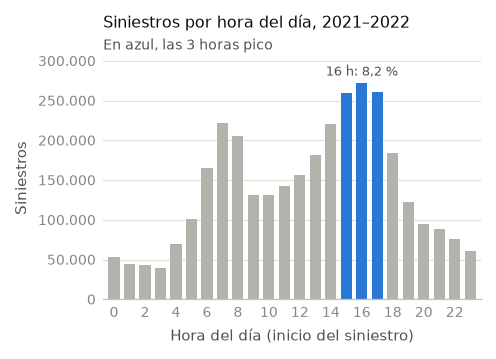

In [12]:
fig, ax = plt.subplots(figsize=(3.25, 2.1))
colores = [AZUL if h in C1_PICO else GRIS for h in C1["hora"]]
ax.bar(C1["hora"], C1["siniestros"], width=0.72, color=colores, linewidth=0)
_h = int(C1.loc[C1["siniestros"].idxmax(), "hora"])         # se rotula solo el máximo
ax.annotate(f"{_h} h: {es(C1.loc[_h, 'pct'])} %", (_h, C1.loc[_h, "siniestros"]), xytext=(0, 2),
            textcoords="offset points", ha="center", va="bottom", fontsize=6, color=TINTA_2)
estilo_ejes(ax)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.7, 23.7)
ax.yaxis.set_major_formatter(plt.FuncFormatter(miles))
ax.set_xlabel("Hora del día (inicio del siniestro)")
ax.set_ylabel("Siniestros")
ax.margins(y=0.12)
ax.set_title(f"Siniestros por hora del día, {C1_DESDE[:4]}–{C1_HASTA[:4]}", loc="left", color=TINTA, pad=14)
ax.text(0, 1.03, f"En azul, las {C1_HORAS_PICO} horas pico", transform=ax.transAxes, fontsize=6.5, color=TINTA_2)
guardar_figura(fig, "c1_distribucion_horaria")

### 8.2 Consulta 4 — Hotspots espaciales: los 5 puntos más peligrosos

**Criterio de peligrosidad.** Para un punto $p$ y un radio $R$, el conjunto de siniestros en su zona de
influencia es $A(p) = \{\, i : d_H(p, x_i) \le R \,\}$, donde $d_H$ es la distancia de Haversine. Se calculan
tres índices y se ordena por el elegido en `C4_CRITERIO`:

| Criterio | Índice | Qué mide |
|---|---|---|
| `graves` (por defecto) | $G(p) = \lvert\{\, i \in A(p) : \text{Severity}_i \ge 3 \,\}\rvert$ | Concentración de siniestros graves |
| `densidad` | $D(p) = \lvert A(p) \rvert$ | Cantidad total de siniestros |
| `ponderado` | $W(p) = \sum_{i \in A(p)} w(\text{Severity}_i)$ | Total ponderado por severidad (`C4_PESOS`) |

Se eligió `graves` porque la densidad sola señala los lugares con más tránsito, no necesariamente los más
peligrosos. Los otros dos índices se informan igual, para comparar.

**Método espacial.** Comparar todos los pares de puntos es inviable ($7{,}7$ millones al cuadrado). Se usa una
grilla y un refinamiento exacto:

1. **Grilla.** Cada siniestro se asigna a una celda de al menos $R$ km de lado. Un grado de latitud mide
   111,2 km; el ancho en longitud se calcula para la latitud 50°, la más desfavorable del territorio continental.
2. **Agregación.** Por celda se obtienen los tres índices y el centroide (promedio de coordenadas).
   Es un `groupBy` que reduce millones de puntos a miles de celdas.
3. **Cota superior.** Como la celda mide al menos $R$, un círculo de radio $R$ centrado dentro de ella queda
   contenido en el bloque de 3 × 3 celdas que la rodea. La suma del bloque es entonces una cota superior
   del índice de cualquier centro de esa celda. Se toman las `C4_CANDIDATOS` celdas de mayor cota.
4. **Refinamiento exacto.** Para cada candidata se calcula la distancia de Haversine entre su centroide y los
   puntos del bloque, y se recalculan los índices solo con los que caen dentro del radio.
5. **Selección.** Se ordena por el índice exacto y se eligen los `C4_TOP` primeros que estén a más de
   `C4_SEPARACION_KM` entre sí, para no informar cinco veces el mismo cruce.

Los centros que se evalúan son los centroides de celda, así que el resultado es exacto dentro de ese conjunto
de centros posibles. **Control de garantía:** si la cota de la mejor celda descartada en el paso 3 no supera
el índice del último hotspot elegido, ninguna celda descartada podía entrar en el ranking. Si no se cumple,
el conjunto de candidatas se cuadruplica y se repiten los pasos 4 y 5 (hasta `C4_CANDIDATOS_MAX`).

- **Spark:** los puntos proyectados se guardan en memoria con `persist()` porque se usan dos veces
  (agregación y refinamiento); así el archivo se lee una sola vez. Las tablas chicas se envían con
  `broadcast` para evitar un *shuffle* de los puntos, y se generan dentro de Spark para que todo el cálculo
  quede en la JVM.
- **Pandas:** mismo algoritmo con `groupby` y `merge`. Ciudad y estado se leen como `category`.

In [13]:
KM_POR_GRADO = R_TIERRA_KM * math.pi / 180                    # 111,19 km por grado de latitud
C4_DLAT = C4_RADIO_KM / KM_POR_GRADO                          # alto de celda, en grados
C4_DLNG = C4_DLAT / math.cos(math.radians(50.0))              # ancho de celda: al menos R km hasta 50° de latitud
C4_COLUMNA = {"graves": "graves", "densidad": "siniestros", "ponderado": "indice"}[C4_CRITERIO]
_VECINOS = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)]

def _c4_tabla_vecinos(cand):
    # Para cada celda candidata, las 9 celdas de su bloque de 3 × 3.
    return [(int(c.cand), int(c.cy + dy), int(c.cx + dx), float(c.lat_c), float(c.lng_c))
            for c in cand.itertuples() for dy, dx in _VECINOS]

def _c4_ordenar_candidatas(cand):
    cand = cand.sort_values(["cota", "cy", "cx"], ascending=[False, True, True]).reset_index(drop=True)
    cand["cand"] = range(len(cand))
    return cand

def _c4_ranking(cand, det, n_celdas):
    # cand: celdas candidatas con centroide y cota. det: índices exactos por candidata, ciudad y estado.
    det = det.copy()
    det[["City", "State"]] = det[["City", "State"]].fillna("")
    tot = det.groupby("cand")[["siniestros", "graves", "indice"]].sum()
    lugar = (det.sort_values(["cand", "siniestros", "City", "State"], ascending=[True, False, True, True])
                .drop_duplicates("cand").set_index("cand"))
    lugar = (lugar["City"] + ", " + lugar["State"]).rename("lugar")
    t = cand.set_index("cand")[["lat_c", "lng_c"]].join(tot, how="inner").join(lugar)
    t = t.sort_values([C4_COLUMNA, "siniestros", "lat_c", "lng_c"], ascending=[False, False, True, True])

    elegidos = []
    for f in t.itertuples():
        if all(haversine_np(f.lat_c, f.lng_c, e.lat_c, e.lng_c) > C4_SEPARACION_KM for e in elegidos):
            elegidos.append(f)
        if len(elegidos) == C4_TOP:
            break
    top = pd.DataFrame({
        "puesto": range(1, len(elegidos) + 1),
        "lat": [round(e.lat_c, 5) for e in elegidos],
        "lng": [round(e.lng_c, 5) for e in elegidos],
        "lugar": [e.lugar for e in elegidos],
        "siniestros": [int(e.siniestros) for e in elegidos],
        "graves": [int(e.graves) for e in elegidos],
        "pct_graves": [100 * e.graves / e.siniestros for e in elegidos],
        "indice_ponderado": [int(e.indice) for e in elegidos],
    })
    # Garantía: ninguna celda descartada (todas con cota menor o igual a la mínima de las candidatas)
    # puede superar al último hotspot elegido.
    ultimo = getattr(elegidos[-1], C4_COLUMNA) if elegidos else 0
    cota_min = float(cand["cota"].min())
    garantia = len(cand) >= n_celdas or (len(elegidos) == C4_TOP and cota_min <= ultimo)
    info = {"celdas_ocupadas": int(n_celdas), "celdas_candidatas": len(cand),
            "cota_minima_candidatas": cota_min, "indice_ultimo_hotspot": float(ultimo),
            "garantia": bool(garantia)}
    return top, info

def c4_spark():
    d = cargar_spark()
    if C4_ESTADO:
        d = d.where(F.col("State") == C4_ESTADO)
    peso = F.lit(0)
    for sev, w in C4_PESOS.items():
        peso = F.when(F.col("Severity") == sev, F.lit(w)).otherwise(peso)

    pts = (d.where(F.col("Start_Lat").isNotNull() & F.col("Start_Lng").isNotNull() & F.col("Severity").isNotNull())
            .select(F.col("Start_Lat").alias("lat"), F.col("Start_Lng").alias("lng"), "City", "State",
                    (F.col("Severity") >= 3).cast("int").alias("grave"), peso.alias("peso"),
                    F.floor(F.col("Start_Lat") / C4_DLAT).cast("long").alias("cy"),
                    F.floor(F.col("Start_Lng") / C4_DLNG).cast("long").alias("cx"))
            .persist(StorageLevel.MEMORY_AND_DISK))
    try:
        celdas = (pts.groupBy("cy", "cx")
                     .agg(F.count("*").alias("siniestros"), F.sum("grave").alias("graves"),
                          F.sum("peso").alias("indice"), F.avg("lat").alias("lat_c"), F.avg("lng").alias("lng_c"))
                     .persist())
        # Las tablas auxiliares se generan dentro de Spark y no desde listas de Python: crear un DataFrame
        # con datos de Python lanza procesos auxiliares que en Windows tardan varios segundos en arrancar.
        vecinos = spark.range(9).select((F.floor(F.col("id") / 3) - 1).alias("dy"),
                                        (F.col("id") % 3 - 1).alias("dx"))
        bloque = (celdas.crossJoin(F.broadcast(vecinos))
                        .select((F.col("cy") + F.col("dy")).alias("cy"), (F.col("cx") + F.col("dx")).alias("cx"),
                                F.col(C4_COLUMNA).alias("v"))
                        .groupBy("cy", "cx").agg(F.sum("v").alias("cota")))
        con_cota = celdas.join(bloque, ["cy", "cx"]).select("cy", "cx", "lat_c", "lng_c", "cota").persist()
        n_celdas = con_cota.count()
        orden = Window.orderBy(F.desc("cota"), "cy", "cx")
        k = C4_CANDIDATOS
        while True:
            mejores = (con_cota.orderBy(F.desc("cota"), "cy", "cx").limit(k)
                               .withColumn("cand", F.row_number().over(orden) - 1).persist())
            cand = a_pandas(mejores).sort_values("cand").reset_index(drop=True)
            cv = (mejores.crossJoin(F.broadcast(vecinos))            # las 9 celdas del bloque de cada candidata
                         .select("cand", (F.col("cy") + F.col("dy")).alias("cy"),
                                 (F.col("cx") + F.col("dx")).alias("cx"), "lat_c", "lng_c"))
            det = a_pandas(pts.join(F.broadcast(cv), ["cy", "cx"])
                              .where(haversine_spark("lat", "lng", "lat_c", "lng_c") <= C4_RADIO_KM)
                              .groupBy("cand", "City", "State")
                              .agg(F.count("*").alias("siniestros"), F.sum("grave").alias("graves"),
                                   F.sum("peso").alias("indice")))
            mejores.unpersist()
            top, info = _c4_ranking(cand, det, n_celdas)
            if info["garantia"] or k >= min(n_celdas, C4_CANDIDATOS_MAX):
                break
            k *= 4                                    # amplía las candidatas y repite el refinamiento
        con_cota.unpersist()
        celdas.unpersist()
    finally:
        pts.unpersist()
    return top, info

def c4_pandas():
    cols = ["Start_Lat", "Start_Lng", "Severity", "City", "State"]
    p = leer_pandas(cols, categorias=["City", "State"]).rename(columns={"Start_Lat": "lat", "Start_Lng": "lng"})
    if C4_ESTADO:
        p = p[p["State"] == C4_ESTADO]
    p = p.dropna(subset=["lat", "lng", "Severity"])
    p["grave"] = (p["Severity"] >= 3).astype("int64")
    p["peso"] = p["Severity"].map(C4_PESOS).fillna(0).astype("int64")
    p["cy"] = np.floor(p["lat"] / C4_DLAT).astype("int64")
    p["cx"] = np.floor(p["lng"] / C4_DLNG).astype("int64")

    celdas = (p.groupby(["cy", "cx"], sort=False)
                .agg(siniestros=("grave", "size"), graves=("grave", "sum"), indice=("peso", "sum"),
                     lat_c=("lat", "mean"), lng_c=("lng", "mean"))
                .reset_index())
    bloque = (pd.concat([pd.DataFrame({"cy": celdas["cy"] + dy, "cx": celdas["cx"] + dx, "cota": celdas[C4_COLUMNA]})
                         for dy, dx in _VECINOS])
                .groupby(["cy", "cx"], sort=False)["cota"].sum().reset_index())
    con_cota = _c4_ordenar_candidatas(celdas.merge(bloque, on=["cy", "cx"])[["cy", "cx", "lat_c", "lng_c", "cota"]])
    n_celdas = len(con_cota)
    k = C4_CANDIDATOS
    while True:
        cand = con_cota.head(k)
        cv = pd.DataFrame(_c4_tabla_vecinos(cand), columns=["cand", "cy", "cx", "lat_c", "lng_c"])
        dentro = p.merge(cv, on=["cy", "cx"])
        dentro = dentro[haversine_np(dentro["lat"], dentro["lng"], dentro["lat_c"], dentro["lng_c"]) <= C4_RADIO_KM].copy()
        dentro[["City", "State"]] = dentro[["City", "State"]].astype(object)   # subconjunto chico: vuelve a texto
        det = (dentro.groupby(["cand", "City", "State"], dropna=False)
                     .agg(siniestros=("grave", "size"), graves=("grave", "sum"), indice=("peso", "sum"))
                     .reset_index())
        top, info = _c4_ranking(cand, det, n_celdas)
        if info["garantia"] or k >= min(n_celdas, C4_CANDIDATOS_MAX):
            break
        k *= 4                                        # amplía las candidatas y repite el refinamiento
    return top, info

C4, C4_INFO = ejecutar("C4 Hotspots", c4_spark, c4_pandas)
guardar_tabla(C4, "c4_hotspots")
print(f"\nRadio: {C4_RADIO_KM} km | ámbito: {C4_ESTADO or 'nacional'} | criterio: {C4_CRITERIO}")
print(f"Celdas ocupadas: {miles(C4_INFO['celdas_ocupadas'])} | candidatas evaluadas con distancia exacta: "
      f"{miles(C4_INFO['celdas_candidatas'])}")
if C4_INFO["celdas_candidatas"] >= C4_INFO["celdas_ocupadas"]:
    print("Garantía: True (se evaluaron todas las celdas ocupadas)")
else:
    print(f"Garantía sobre las celdas descartadas: {C4_INFO['garantia']} "
          f"(cota máxima de las descartadas: {C4_INFO['cota_minima_candidatas']:.0f}; "
          f"índice del último hotspot: {C4_INFO['indice_ultimo_hotspot']:.0f})")
if not C4_INFO["garantia"]:
    print("ATENCIÓN: no se alcanzó la garantía; aumentá C4_CANDIDATOS_MAX y volvé a ejecutar esta celda.")
C4.round({"pct_graves": 1})

[csv     | Spark ] C4 Hotspots:    8.86 s  (promedio de 3: 10.65 s)
[csv     | Pandas] C4 Hotspots:   22.40 s  (promedio de 3: 22.62 s)
Mismo resultado en ambos motores: True

Radio: 2.0 km | ámbito: nacional | criterio: graves
Celdas ocupadas: 182.594 | candidatas evaluadas con distancia exacta: 300
Garantía sobre las celdas descartadas: True (cota máxima de las descartadas: 2996; índice del último hotspot: 3378)


,puesto,lat,lng,lugar,siniestros,graves,pct_graves,indice_ponderado
0,1,33.74921,-84.38250,"Atlanta, GA",8424,4936,58.6,27842
1,2,40.84094,-73.93416,"New York, NY",13176,4894,37.1,36931
2,3,33.78713,-84.39080,"Atlanta, GA",7606,3999,52.6,24098
3,4,34.02511,-118.27151,"Los Angeles, CA",10540,3969,37.7,29386
4,5,32.78078,-96.80332,"Dallas, TX",10787,3378,31.3,28617


### 8.3 Consulta 5 — Distancia y duración promedio inicio–fin, por severidad

**Definición.** Por cada nivel de `Severity`:

- **Distancia inicio–fin:** Haversine entre (`Start_Lat`, `Start_Lng`) y (`End_Lat`, `End_Lng`), en km.
  Solo se puede calcular donde hay coordenadas de fin (faltan en cerca del 44 % de las filas); la tabla
  informa cuántas filas entran en el promedio. Como control se agrega el promedio de `Distance_mi`
  (la extensión afectada que informa el dataset) convertido a km.
- **Duración:** `End_Time − Start_Time`, en minutos. Hay duraciones extremas (siniestros que figuran
  abiertos durante meses) que arrastran la media, así que se informan tres valores: la **media** sobre
  todas las filas, que es lo que pide la consigna; la **media acotada**, que excluye duraciones negativas
  o mayores a `DURACION_MAX_DIAS` días; y la **mediana**. La tabla indica cuántas filas quedan fuera del
  rango.

En Spark la distancia se calcula con funciones nativas de columna, no con una UDF de Python, para que el
cálculo quede dentro de la JVM y pueda compilarse (Tungsten).

In [14]:
_C5_COLS = ["Severity", "siniestros", "con_coord_fin", "pct_con_coord_fin", "dist_media_km",
            "dist_reportada_media_km", "dur_media_min", "dur_media_acotada_min", "dur_mediana_min",
            "dur_fuera_de_rango"]
MILLA_KM = 1.609344

def _c5_formato(t):
    t = t.sort_values("Severity").reset_index(drop=True)
    t["pct_con_coord_fin"] = 100 * t["con_coord_fin"] / t["siniestros"]
    return t[_C5_COLS]

def c5_spark():
    d = cargar_spark().select(
        "Severity",
        haversine_spark("Start_Lat", "Start_Lng", "End_Lat", "End_Lng").alias("dist_km"),
        (F.col("Distance_mi") * MILLA_KM).alias("dist_rep_km"),
        ((F.unix_timestamp("End_Time") - F.unix_timestamp("Start_Time")) / 60).alias("dur_min"))
    d = d.withColumn("dur_ok", F.when(F.col("dur_min").between(0, DUR_MAX_MIN), F.col("dur_min")))
    r = d.groupBy("Severity").agg(
        F.count("*").alias("siniestros"),
        F.count("dist_km").alias("con_coord_fin"),
        F.avg("dist_km").alias("dist_media_km"),
        F.avg("dist_rep_km").alias("dist_reportada_media_km"),
        F.avg("dur_min").alias("dur_media_min"),
        F.avg("dur_ok").alias("dur_media_acotada_min"),
        F.expr("percentile(dur_min, 0.5)").alias("dur_mediana_min"),
        (F.count("dur_min") - F.count("dur_ok")).alias("dur_fuera_de_rango"))
    return _c5_formato(a_pandas(r))

def c5_pandas():
    p = leer_pandas(["Severity", "Start_Time", "End_Time", "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance_mi"])
    p["dist_km"] = haversine_np(p["Start_Lat"], p["Start_Lng"], p["End_Lat"], p["End_Lng"])
    p["dist_rep_km"] = p["Distance_mi"] * MILLA_KM
    p["dur_min"] = (p["End_Time"] - p["Start_Time"]).dt.total_seconds() / 60
    p["dur_ok"] = p["dur_min"].where(p["dur_min"].between(0, DUR_MAX_MIN))
    r = (p.groupby("Severity")
          .agg(siniestros=("Severity", "size"), con_coord_fin=("dist_km", "count"),
               dist_media_km=("dist_km", "mean"), dist_reportada_media_km=("dist_rep_km", "mean"),
               dur_media_min=("dur_min", "mean"), dur_media_acotada_min=("dur_ok", "mean"),
               dur_mediana_min=("dur_min", "median"),
               _con_dur=("dur_min", "count"), _en_rango=("dur_ok", "count"))
          .reset_index())
    r["dur_fuera_de_rango"] = r["_con_dur"] - r["_en_rango"]
    return _c5_formato(r)

C5 = ejecutar("C5 Distancia y duración", c5_spark, c5_pandas)
guardar_tabla(C5, "c5_distancia_duracion")
print(f"Duraciones fuera de rango (negativas o de más de {DURACION_MAX_DIAS} días): "
      f"{miles(C5['dur_fuera_de_rango'].sum())} filas "
      f"({es(100 * C5['dur_fuera_de_rango'].sum() / TOTAL_FILAS, 2)} % del total)")
C5.round({"pct_con_coord_fin": 1, "dist_media_km": 3, "dist_reportada_media_km": 3,
          "dur_media_min": 1, "dur_media_acotada_min": 1, "dur_mediana_min": 1})

[csv     | Spark ] C5 Distancia y duración:    5.55 s  (promedio de 3: 5.74 s)
[csv     | Pandas] C5 Distancia y duración:   29.63 s  (promedio de 3: 29.80 s)
Mismo resultado en ambos motores: True
Duraciones fuera de rango (negativas o de más de 7 días): 6.824 filas (0,09 % del total)


,Severity,siniestros,con_coord_fin,pct_con_coord_fin,dist_media_km,dist_reportada_media_km,dur_media_min,dur_media_acotada_min,dur_mediana_min,dur_fuera_de_rango
0,1,67366,28206,41.9,0.324,0.184,53.8,46.0,44.8,1
1,2,6156981,3945613,64.1,1.337,0.909,485.4,122.6,77.6,5536
2,3,1299337,161528,12.4,0.974,0.682,74.8,68.5,44.4,86
3,4,204710,190285,93.0,2.020,2.407,1685.3,217.6,128.4,1201


### 8.4 Consulta 9 — Las 10 intersecciones más críticas, por procesamiento de texto

**Qué dicen los datos sobre los patrones sugeridos.** El enunciado propone buscar `and`, `&` y `corner`.
Una exploración previa del texto real mostró que en este dataset esos patrones casi nunca indican un cruce:

| Patrón | Filas | Qué es en realidad |
|---|---|---|
| `and` | 6,1 % | El 59 % son tramos (`between A and B`); el resto, frases como `lane blocked and shoulder blocked` |
| `&` | 0,3 % | Numeración de carriles (`#1 & #2 lane blocked`) |
| `corner` | 0,03 % | Nombres de calles (`Rice Corner Rd`) |

Los cruces están escritos de otra forma, que depende de la fuente del dato:

- **Fuentes 2 y 3:** `Accident on X at Y` (la vía del siniestro y la vía que la cruza están en la descripción).
- **Fuente 1:** `At Y - Accident`, donde la vía del siniestro está en la columna `Street`, y
  `Slow traffic on X at Y due to accident`.

**Definición.** Un *cruce* es un par no ordenado de vías distintas, dentro de una ciudad y un estado,
obtenido con dos reglas que se aplican igual en los dos motores:

| Regla | Texto | Vía 1 | Vía 2 |
|---|---|---|---|
| R1 | `… on X at Y` | X, de `Description` | Y, de `Description` |
| R2 | `At Y - …` o `Closed at Y - …` | `Street` | Y, de `Description` |

Normalización de cada vía: mayúsculas (solo de las letras sin acento, para que los dos motores hagan
exactamente lo mismo); se quita el sentido de circulación (`Northbound`, `both ways`, letra final
`N/S/E/W`), lo que sigue a `due to` y los paréntesis; si hay nombres alternativos separados por `/` o
` - `, queda el primero.

Cada fila analizada queda en una de cuatro categorías:

| Categoría | Criterio |
|---|---|
| **Esquina entre calles** | Las dos vías son calles con nombre. Es la respuesta principal de la consulta |
| **Cruce con ruta o autopista** | Alguna de las vías es una ruta numerada (`I-95`, `US-101`, `CA-99`) o una autopista (`Hwy`, `Fwy`, `Expy`, `Tpke`). Muchos son enlaces a distinto nivel, por eso se informan aparte |
| **Salida de autopista** | El texto dice `at Exit 12 …`. No se arma par |
| **Sin estructura de cruce** | Tramos (`between A and B`, `from A to B`), cercanías (`near Y`) u otros textos |

La consulta también cuenta las filas que contienen los patrones del enunciado y cuántas de ellas quedan
ubicadas en un cruce, para respaldar con números la decisión de no usarlos como criterio.

Limitaciones: con el texto solo no se distingue un cruce a nivel de un enlace a distinto
nivel; los nombres de vías no están unificados entre fuentes (`US-19` y `US Highway 19` cuentan por
separado); y la fuente 1 dejó de informar la vía transversal en sus datos más recientes, por lo que los
cruces identificados provienen sobre todo de las fuentes 2 y 3.

Las expresiones regulares usan solo sintaxis común a Java (Spark) y Python (Pandas), y evitan las
construcciones cuyo significado cambia entre motores o versiones cuando el texto trae caracteres no
ASCII: el límite de palabra `\b`, la opción `(?i)` y el paso a mayúsculas de letras acentuadas. Los
límites de palabra y las mayúsculas se escriben de forma explícita.

In [15]:
# Blancos y saltos de línea (incluye espacio duro y separadores Unicode), como caracteres literales.
_BLANCOS = "[ \t\r\n\u00a0\u0085\u2028\u2029]+"
_MIN, _MAY = "abcdefghijklmnopqrstuvwxyz", "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
_IZQ, _DER = r"(?:^|[^A-Za-z0-9_])", r"(?:[^A-Za-z0-9_]|$)"       # límites de palabra, explícitos

def _palabra(alternativas):
    return _IZQ + "(?:" + alternativas + ")" + _DER

C9_PRE_DESC = _palabra("[Aa][Tt]|[Aa][Nn][Dd]|[Cc][Oo][Rr][Nn][Ee][Rr]") + "|&"   # filas que pueden aportar algo
C9_PRE_CALLE = _palabra("[Aa][Nn][Dd]|[Cc][Oo][Rr][Nn][Ee][Rr]") + "|&"
C9_R1 = _IZQ + r"ON ((?:(?! ON ).)+?) AT ([^.]+)"          # ... ON x AT y
C9_R2 = r"^(?:CLOSED )?AT (.+?) - "                        # AT y - ...
C9_SALIDA = _palabra("EXITS?")
C9_RUTA = (_IZQ + r"(?:[A-Z]{1,3}-[0-9]|(?:I|US|SR|CR|RT|RTE|ROUTE|HWY|HIGHWAY|ROAD) [0-9])|"
           + _palabra("INTERSTATE|HIGHWAY|HWY|FWY|FREEWAY|EXPY|EXPRESSWAY|TPKE|TURNPIKE|TOLLWAY"))
C9_COLA = r" (?:DUE TO |- ).*$"                            # "... due to accident" y alias "A - B"
C9_ALIAS = r" ?/(?!(?<= [0-9]/)[0-9](?: |$)).*$"          # alias "A/B": queda el primero (no corta "1/2")
C9_PARENTESIS = r" ?\([^)]*\)"
C9_SENTIDO = r" (?:NORTHBOUND|SOUTHBOUND|EASTBOUND|WESTBOUND|BOTH WAYS|[NSEW]B?)$"
C9_AND, C9_CORNER = _palabra("AND"), _palabra("CORNER")
C9_BETWEEN = _palabra("BETWEEN") + ".*" + _palabra("AND")
C9_GUARDAR = 30                                            # filas de cada ranking que se guardan en CSV
_C9_CATEGORIAS = ["Esquina entre calles", "Cruce con ruta o autopista", "Salida de autopista",
                  "Sin estructura de cruce"]
_C9_MEDIDAS = ["Filas con 'and'", "  de ellas, tramos (between ... and)", "Filas con '&'", "Filas con 'corner'",
               "Filas con algún patrón del enunciado", "  de ellas, ubicadas en un cruce"]

def _c9_ranking(top):
    top = top.copy()
    top["cruce"] = top["via_a"] + " & " + top["via_b"]
    top = (top.sort_values(["siniestros", "via_a", "via_b", "City", "State"],
                           ascending=[False, True, True, True, True]).head(C9_GUARDAR).reset_index(drop=True))
    top.insert(0, "puesto", range(1, len(top) + 1))
    return top[["puesto", "cruce", "City", "State", "siniestros"]]

def _c9_formato(top_calles, top_rutas, categorias, patrones):
    orden = [(c, r) for c in _C9_CATEGORIAS[:2] for r in ("R1", "R2")] + [(c, "") for c in _C9_CATEGORIAS[2:]]
    cat = categorias.set_index(["categoria", "regla"])["filas"]
    cat = pd.DataFrame({"categoria": [c for c, _ in orden], "regla": [r for _, r in orden],
                        "filas": [int(cat.get(k, 0)) for k in orden]})
    pat = pd.DataFrame({"medida": _C9_MEDIDAS, "filas": [int(patrones[m]) for m in _C9_MEDIDAS]})
    return _c9_ranking(top_calles), _c9_ranking(top_rutas), cat, pat

def _c9_filas_spark():
    # Filas que pasan el prefiltro, con su categoría y el par de vías ya normalizado.
    def normalizar(c):
        return F.translate(F.trim(F.regexp_replace(F.coalesce(F.col(c), F.lit("")), _BLANCOS, " ")), _MIN, _MAY)
    def limpiar(v):
        for patron in (C9_COLA, C9_ALIAS, C9_PARENTESIS):
            v = F.regexp_replace(v, patron, "")
        v = F.regexp_replace(F.trim(v), C9_SENTIDO, "")
        return F.trim(v)
    def valido(x, y, x_crudo, y_crudo):
        # "ok", "salida" o "" según lo que se pueda concluir del par (x, y)
        hay = (x_crudo != "") & (y_crudo != "")
        salida = x_crudo.rlike(C9_SALIDA) | y_crudo.rlike(C9_SALIDA)
        return (F.when(~hay, "").when(salida, "salida")
                 .when((x == "") | (y == "") | (x == y), "").otherwise("ok"))

    d = (cargar_spark()
         .where(F.col("Description").rlike(C9_PRE_DESC) | F.col("Street").rlike(C9_PRE_CALLE))
         .select(normalizar("Street").alias("calle"), normalizar("Description").alias("desc"),
                 F.coalesce(F.col("City"), F.lit("")).alias("City"),
                 F.coalesce(F.col("State"), F.lit("")).alias("State")))
    x1c, y1c = F.regexp_extract("desc", C9_R1, 1), F.regexp_extract("desc", C9_R1, 2)
    y2c = F.regexp_extract("desc", C9_R2, 1)
    x2c = F.when(y2c != "", F.col("calle")).otherwise(F.lit(""))
    x1, y1, x2, y2 = limpiar(x1c), limpiar(y1c), limpiar(x2c), limpiar(y2c)
    e1, e2 = valido(x1, y1, x1c, y1c), valido(x2, y2, x2c, y2c)
    regla = F.when(e1 == "ok", "R1").when(e2 == "ok", "R2").otherwise(F.lit(""))
    x = F.when(e1 == "ok", x1).when(e2 == "ok", x2).otherwise(F.lit(""))
    y = F.when(e1 == "ok", y1).when(e2 == "ok", y2).otherwise(F.lit(""))
    con_ruta = x.rlike(C9_RUTA) | y.rlike(C9_RUTA)
    categoria = (F.when((regla != "") & ~con_ruta, _C9_CATEGORIAS[0])
                  .when(regla != "", _C9_CATEGORIAS[1])
                  .when((e1 == "salida") | (e2 == "salida"), _C9_CATEGORIAS[2])
                  .otherwise(_C9_CATEGORIAS[3]))
    ambos = F.concat_ws(" | ", "calle", "desc")
    return d.select(
        "calle", "desc", "City", "State", categoria.alias("categoria"), regla.alias("regla"),
        F.least(x, y).alias("via_a"), F.greatest(x, y).alias("via_b"),
        ambos.rlike(C9_AND).cast("int").alias("p_and"),
        F.col("desc").rlike(C9_BETWEEN).cast("int").alias("p_between"),
        ambos.contains("&").cast("int").alias("p_amp"),
        ambos.rlike(C9_CORNER).cast("int").alias("p_corner"))

def c9_spark():
    f = _c9_filas_spark().drop("calle", "desc").persist(StorageLevel.MEMORY_AND_DISK)
    try:
        en_cruce = (F.col("regla") != "").cast("int")
        algun = F.greatest("p_and", "p_amp", "p_corner")
        fila = f.agg(F.sum("p_and"), F.sum("p_between"), F.sum("p_amp"), F.sum("p_corner"),
                     F.sum(algun), F.sum(algun * en_cruce)).first()
        patrones = {m: (fila[i] or 0) for i, m in enumerate(_C9_MEDIDAS)}
        categorias = a_pandas(f.groupBy("categoria", "regla").agg(F.count("*").alias("filas")))
        def ranking(categoria):
            return a_pandas(f.where(F.col("categoria") == categoria)
                             .groupBy("via_a", "via_b", "City", "State").agg(F.count("*").alias("siniestros"))
                             .orderBy(F.desc("siniestros"), "via_a", "via_b", "City", "State").limit(C9_GUARDAR))
        top_calles, top_rutas = ranking(_C9_CATEGORIAS[0]), ranking(_C9_CATEGORIAS[1])
    finally:
        f.unpersist()
    return _c9_formato(top_calles, top_rutas, categorias, patrones)

def c9_pandas():
    p = leer_pandas(["Street", "Description", "City", "State"], categorias=["City", "State"])
    marca = (p["Description"].str.contains(C9_PRE_DESC, regex=True, na=False)
             | p["Street"].str.contains(C9_PRE_CALLE, regex=True, na=False))
    p = p[marca].copy()
    def normalizar(s):
        return (s.fillna("").astype(str).str.replace(_BLANCOS, " ", regex=True).str.strip(" ")
                 .str.translate(str.maketrans(_MIN, _MAY)))
    def limpiar(v):
        for patron in (C9_COLA, C9_ALIAS, C9_PARENTESIS):
            v = v.str.replace(patron, "", regex=True)
        return v.str.strip(" ").str.replace(C9_SENTIDO, "", regex=True).str.strip(" ")
    def valido(x, y, x_crudo, y_crudo):
        hay = (x_crudo != "") & (y_crudo != "")
        salida = x_crudo.str.contains(C9_SALIDA, regex=True) | y_crudo.str.contains(C9_SALIDA, regex=True)
        vacio = (x == "") | (y == "") | (x == y)
        return np.select([~hay, salida, vacio], ["", "salida", ""], default="ok")

    calle, desc = normalizar(p["Street"]), normalizar(p["Description"])
    r1 = desc.str.extract(C9_R1).fillna("")
    x1c, y1c = r1[0], r1[1]
    y2c = desc.str.extract(C9_R2)[0].fillna("")
    x2c = calle.where(y2c != "", "")
    x1, y1, x2, y2 = limpiar(x1c), limpiar(y1c), limpiar(x2c), limpiar(y2c)
    e1, e2 = valido(x1, y1, x1c, y1c), valido(x2, y2, x2c, y2c)
    p["regla"] = np.select([e1 == "ok", e2 == "ok"], ["R1", "R2"], default="")
    x = pd.Series(np.select([e1 == "ok", e2 == "ok"], [x1, x2], default=""), index=p.index)
    y = pd.Series(np.select([e1 == "ok", e2 == "ok"], [y1, y2], default=""), index=p.index)
    con_ruta = (x.str.contains(C9_RUTA, regex=True) | y.str.contains(C9_RUTA, regex=True)).to_numpy()
    hay_par = (p["regla"] != "").to_numpy()
    p["categoria"] = np.select(
        [hay_par & ~con_ruta, hay_par, (e1 == "salida") | (e2 == "salida")], _C9_CATEGORIAS[:3],
        default=_C9_CATEGORIAS[3])
    p["via_a"] = np.where(x <= y, x, y)
    p["via_b"] = np.where(x <= y, y, x)
    p[["City", "State"]] = p[["City", "State"]].astype(object).fillna("").astype(str)

    ambos = calle + " | " + desc
    p_and = ambos.str.contains(C9_AND, regex=True)
    p_between = desc.str.contains(C9_BETWEEN, regex=True)
    p_amp = ambos.str.contains("&", regex=False)
    p_corner = ambos.str.contains(C9_CORNER, regex=True)
    algun = p_and | p_amp | p_corner
    valores = [p_and.sum(), p_between.sum(), p_amp.sum(), p_corner.sum(), algun.sum(), (algun & hay_par).sum()]
    patrones = dict(zip(_C9_MEDIDAS, valores))
    categorias = p.groupby(["categoria", "regla"]).size().rename("filas").reset_index()
    def ranking(categoria):
        return (p[p["categoria"] == categoria].groupby(["via_a", "via_b", "City", "State"]).size()
                .rename("siniestros").reset_index())
    return _c9_formato(ranking(_C9_CATEGORIAS[0]), ranking(_C9_CATEGORIAS[1]), categorias, patrones)

C9_TOP_CALLES, C9_TOP_RUTAS, C9_CATEGORIAS, C9_PATRONES = (
    t.copy() for t in ejecutar("C9 Intersecciones", c9_spark, c9_pandas))
C9 = C9_TOP_CALLES.head(10)                 # respuesta de la consulta: esquinas entre calles
C9_RUTAS = C9_TOP_RUTAS.head(10)            # complementaria: cruces con ruta o autopista
C9_CATEGORIAS["pct_del_total"] = (100 * C9_CATEGORIAS["filas"] / TOTAL_FILAS).round(2)
C9_PATRONES["pct_del_total"] = (100 * C9_PATRONES["filas"] / TOTAL_FILAS).round(2)
guardar_tabla(C9, "c9_intersecciones")
guardar_tabla(C9_RUTAS, "c9_cruces_con_ruta")
guardar_tabla(C9_TOP_CALLES, "c9_top30_esquinas")
guardar_tabla(C9_TOP_RUTAS, "c9_top30_cruces_con_ruta")
guardar_tabla(C9_CATEGORIAS, "c9_categorias")
guardar_tabla(C9_PATRONES, "c9_patrones_enunciado")

_por_cat = C9_CATEGORIAS.groupby("categoria", sort=False)["filas"].sum()
print(f"\nSiniestros en esquinas entre calles:      {miles(_por_cat[_C9_CATEGORIAS[0]])} "
      f"({es(100 * _por_cat[_C9_CATEGORIAS[0]] / TOTAL_FILAS)} % del total)")
print(f"Siniestros en cruces con ruta o autopista: {miles(_por_cat[_C9_CATEGORIAS[1]])} "
      f"({es(100 * _por_cat[_C9_CATEGORIAS[1]] / TOTAL_FILAS)} % del total)")
print("\nPatrones del enunciado:")
display(C9_PATRONES)
print("Clasificación de las filas analizadas:")
display(C9_CATEGORIAS)
print("Cruces con ruta o autopista con más siniestros (complementaria):")
display(C9_RUTAS)
print("Las 10 esquinas entre calles con más siniestros (respuesta de la consulta):")
C9

[csv     | Spark ] C9 Intersecciones:   60.69 s  (promedio de 3: 61.82 s)
[csv     | Pandas] C9 Intersecciones:   79.77 s  (promedio de 3: 81.19 s)
Mismo resultado en ambos motores: True

Siniestros en esquinas entre calles:      865.084 (11,2 % del total)
Siniestros en cruces con ruta o autopista: 1.465.166 (19,0 % del total)

Patrones del enunciado:


,medida,filas,pct_del_total
0,Filas con 'and',468451,6.06
1,"de ellas, tramos (between ... and)",277364,3.59
2,Filas con '&',22936,0.30
3,Filas con 'corner',2270,0.03
4,Filas con algún patrón del enunciado,489651,6.34
5,"de ellas, ubicadas en un cruce",57640,0.75


Clasificación de las filas analizadas:


,categoria,regla,filas,pct_del_total
0,Esquina entre calles,R1,723247,9.36
1,Esquina entre calles,R2,141837,1.84
2,Cruce con ruta o autopista,R1,1071515,13.86
3,Cruce con ruta o autopista,R2,393651,5.09
4,Salida de autopista,,1197815,15.50
5,Sin estructura de cruce,,459541,5.95


Cruces con ruta o autopista con más siniestros (complementaria):


,puesto,cruce,City,State,siniestros
0,1,CA-91 & I-15,Corona,CA,1134
1,2,I-5 & I-605,Downey,CA,721
2,3,I-405 & US-101,Sherman Oaks,CA,626
3,4,I-10 & I-605,Baldwin Park,CA,568
4,5,CA-57 & CA-60,Diamond Bar,CA,554
5,6,I-10 & I-405,Los Angeles,CA,548
6,7,CA-24 & I-680,Walnut Creek,CA,547
7,8,I-610 & I-69,Houston,TX,539
8,9,SAM HOUSTON PKWY & TX-8,Houston,TX,529
9,10,12TH AVE & CA-99,Sacramento,CA,513


Las 10 esquinas entre calles con más siniestros (respuesta de la consulta):


,puesto,cruce,City,State,siniestros
0,1,CENTRAL AVE & SHARON AMITY RD,Charlotte,NC,292
1,2,MONROE RD & SARDIS RD,Charlotte,NC,261
2,3,CENTRAL AVE & EASTWAY DR,Charlotte,NC,260
3,4,SOUTH BLVD & TYVOLA RD,Charlotte,NC,252
4,5,CLEMSON RD & HARD SCRABBLE RD,Columbia,SC,238
5,6,BEATTIES FORD RD & SUNSET RD,Charlotte,NC,223
6,7,FAIRVIEW RD & SHARON RD,Charlotte,NC,222
7,8,JACKSON AVE & SPRAIN BROOK PKWY,Yonkers,NY,218
8,9,NEW BERN AVE & SUNNYBROOK RD,Raleigh,NC,206
9,10,EASTWAY DR & THE PLAZA,Charlotte,NC,205


**Muestra para revisar las reglas.** Esta celda no se mide. Muestra ejemplos al azar de cada categoría,
para comprobar a ojo que la extracción hace lo esperado.

In [16]:
_m = _c9_filas_spark().persist(StorageLevel.MEMORY_AND_DISK)
pd.set_option("display.max_colwidth", 150)
for _categoria in _C9_CATEGORIAS:
    _sub = _m.where(F.col("categoria") == _categoria)
    _n = _sub.count()
    print(f"{_categoria}: {miles(_n)} filas")
    if _n:
        display(a_pandas(_sub.sample(fraction=min(1.0, 60 / _n), seed=11)
                             .select("regla", "via_a", "via_b", "calle", "desc").limit(10)))
_m.unpersist();

Esquina entre calles: 865.084 filas


,regla,via_a,via_b,calle,desc
0,R1,EASTERN AVE,PUENTE WAY,EASTERN AVE,ACCIDENT ON PUENTE WAY AT EASTERN AVE.
1,R1,BREA CANYON RD,VALLEY BLVD,VALLEY BLVD,ACCIDENT ON VALLEY BLVD EASTBOUND AT BREA CANYON RD.
2,R1,22ND ST,OAKBROOK CTR,W 22ND ST,ACCIDENT ON 22ND ST AT OAKBROOK CTR.
3,R1,HOME AVE,JAMES H MCGEE BLVD,S JAMES H MCGEE BLVD,ACCIDENT ON HOME AVE AT JAMES H MCGEE BLVD.
4,R1,BACKLICK RD,BRADDOCK RD,BACKLICK RD,LEFT LANE CLOSED DUE TO ACCIDENT ON BRADDOCK RD SOUTHBOUND AT BACKLICK RD.
5,R1,5TH AVE,BROAD ST,BROAD ST,ACCIDENT ON BROAD ST SOUTHBOUND AT 5TH AVE.
6,R1,DONOP RD,SOUTHTON RD,SOUTHTON RD,ACCIDENT ON SOUTHTON RD AT DONOP RD.
7,R1,FULTON ST,LAFAYETTE AVE,FULTON ST E,ACCIDENT ON FULTON ST AT LAFAYETTE AVE.
8,R1,HYLAN BLVD,SEAVIEW AVE,SEAVIEW AVE,ACCIDENT ON SEAVIEW AVE AT HYLAN BLVD.
9,R1,FLICKER HILL RD,WARM SPRINGS RD,WARM SPRINGS RD,CRASH ON WARM SPRINGS RD AT FLICKER HILL RD.


Cruce con ruta o autopista: 1.465.166 filas


,regla,via_a,via_b,calle,desc
0,R1,HANNAWAY DR,US-301,US HIGHWAY 301 S,ACCIDENT ON US-301 NORTHBOUND AT HANNAWAY DR.
1,R1,IL-50 CICERO AVE,VOLLMER RD,S CICERO AVE,SLOW TRAFFIC DUE TO ACCIDENT ON IL-50 CICERO AVE AT VOLLMER RD.
2,R1,CHESTER AVE,COUNTY HWY-667 BROADWAY,BROADWAY,ACCIDENT ON COUNTY HWY-667 BROADWAY BOTH WAYS AT CHESTER AVE.
3,R1,OLD HUMBLE RD,TX-8,TX-8 E,ACCIDENT ON OLD HUMBLE RD AT TX-8.
4,R1,JOHN RALSTON RD,US-90 BUS BEAUMONT HWY,JOHN RALSTON RD,ACCIDENT ON US-90 BUS BEAUMONT HWY AT JOHN RALSTON RD.
5,R1,CHERRY AVE,I-405,SAN DIEGO FWY S,ACCIDENT ON I-405 NORTHBOUND AT CHERRY AVE.
6,R1,CENTRAL AVE,COUNTY HWY-4 ROSELLE RD,S ROSELLE RD,ACCIDENT ON CENTRAL AVE AT COUNTY HWY-4 ROSELLE RD.
7,R1,BIG HOLLOW RD,US-150 WAR MEMORIAL DR,W WAR MEMORIAL DR,ACCIDENT ON BIG HOLLOW RD AT US-150 WAR MEMORIAL DR.
8,R1,DIVISION AVE,I-35,I-35 S,ONE LANE BLOCKED DUE TO CRASH ON I-35 NORTHBOUND AT DIVISION AVE.
9,R1,LA-37 GREENWELL SPRINGS RD,LA-946 JOOR RD,OAK VILLA,ONE LANE BLOCKED DUE TO CRASH ON LA-37 GREENWELL SPRINGS RD AT LA-946 JOOR RD.


Salida de autopista: 1.197.815 filas


,regla,via_a,via_b,calle,desc
0,,,,RIVERSIDE FWY E,ACCIDENT ON CA-91 EASTBOUND AT EXIT 45 CA-71.
1,,,,CA-78 W,ACCIDENT ON CA-78 EASTBOUND AT EXIT 7 SUNSET DR.
2,,,,I-5 N,ACCIDENT ON I-5 NORTHBOUND AT EXIT 74 EL CAMINO REAL.
3,,,,GA-403 S,QUEUEING TRAFFIC AND 2ND LANE BLOCKED DUE TO ACCIDENT ON I-85 NORTHBOUND AT EXIT 94 CHAMBLEE TUCKER RD.
4,,,,BUICK FWY S,ACCIDENT ON I-475 NORTHBOUND AT EXIT 13 SAGINAW ST.
5,,,,I-95 S,ACCIDENT ON I-95 SOUTHBOUND AT EXIT 4 INDIAN FIELD RD.
6,,,,I-287 W,LEFT LANE BLOCKED DUE TO ACCIDENT ON I-87 I-287 NORTHBOUND AT EXIT 9 US-9 BROADWAY.
7,,,,I-96 E,LEFT HAND SHOULDER BLOCKED AND LEFT LANE BLOCKED DUE TO ACCIDENT ON I-96 EASTBOUND AT EXIT 189 GRAND BLVD.
8,,,,SHERIDAN EXPY N,LEFT LANE BLOCKED DUE TO ACCIDENT ON I-278 BRUCKNER EXPY EASTBOUND AT EXITS 49 50 I-895 SHERIDAN EXPY.
9,,,,I-20,TWO LANES BLOCKED DUE TO CRASH ON I-20 WESTBOUND AT EXIT 71 PANOLA RD.


Sin estructura de cruce: 459.541 filas


,regla,via_a,via_b,calle,desc
0,,,,W MANCHESTER AVE,THREE LANES BLOCKED AND RIGHT HAND SHOULDER BLOCKED DUE TO ACCIDENT ON I-110 NORTHBOUND BEFORE EXIT 16 CA-42 MANCHESTER AVE.
1,,,,I-84 W,RIGHT LANE CLOSED DUE TO ACCIDENT ON I-84 YANKEE EXPY WESTBOUND BETWEEN I-84 EXIT 29 AND I-84 EXIT 27.
2,,,,CAMERON PARK DR,RIGHT HAND SHOULDER BLOCKED DUE TO ACCIDENT ON US-50 EASTBOUND BETWEEN EXIT 34 CAMBRIDGE RD AND EXIT 35 CAMERON PARK DR.
3,,,,I-10 W,RIGHT SHOULDER AND #2 LANE BLOCKED DUE TO ACCIDENT ON I-10 WESTBOUND NEAR EXIT 26B CA-19 ROSEMEAD BLVD.
4,,,,BRISTOL LN,ACCIDENT ON BARRINGTON RD BETWEEN IL-19 IRVING PARK RD AND BRISTOL LN.
5,,,,STARLIGHT DR,ACCIDENT ON PA-24 CAPE HORN RD BETWEEN MEADOW HILL DR AND STARLIGHT DR.
6,,,,WOOD ST,LANE BLOCKED DUE TO ACCIDENT ON I-95 SOUTHBOUND BETWEEN EXIT 23 ARAMINGO AVE AND EXIT 22 6TH ST.
7,,,,HOLMES AVE NW,ENTRY RAMP TO N MEMORIAL PKWY SOUTHBOUND AT EXITS 19A 19B 19C FROM I-565 EASTBOUND LANE BLOCKED DUE TO ACCIDENT.
8,,,,I-20 E,ONE LANE BLOCKED AND LEFT HAND SHOULDER BLOCKED DUE TO ACCIDENT ON I-20 EASTBOUND BETWEEN EXIT 77 CR-85 BUTTERMILK RD AND EXIT 86 CR-59 COVERED BR...
9,,,,GLENN ANDERSON FWY E,EXIT RAMP FROM I-105 EASTBOUND AT EXIT 14 TO GARFIELD AVE EASTBOUND LANE BLOCKED DUE TO ACCIDENT.


### 8.5 Consulta 10 — Velocidad de despeje según iluminación y tipo de día

**Definición.** Tiempo de despeje = `End_Time − Start_Time`, en minutos. Se compara:

- **Día vs. noche**, con dos definiciones: `Sunrise_Sunset` (salida y puesta del sol) y
  `Astronomical_Twilight` (crepúsculo astronómico, que considera noche solo la oscuridad total).
- **Día hábil vs. fin de semana**, según el día de la semana de `Start_Time` (sábado y domingo son fin de semana).

Se informan la media, la media acotada y la mediana, por la misma razón que en la consulta 5.
Las filas sin dato de iluminación se excluyen del indicador correspondiente.

En Spark, las dos definiciones se calculan en una sola pasada: `stack` convierte las dos columnas de
iluminación en filas (indicador, valor) antes de agrupar. En Pandas se usa `melt`.

In [17]:
_C10_INDICADORES = ["Sunrise_Sunset", "Astronomical_Twilight"]
_C10_LUZ = {"Day": "Día", "Night": "Noche"}

def _c10_formato(t):
    t = t.copy()
    t["luz"] = t["luz"].map(_C10_LUZ)
    t["indicador"] = pd.Categorical(t["indicador"], _C10_INDICADORES, ordered=True)
    t["luz"] = pd.Categorical(t["luz"], ["Día", "Noche"], ordered=True)
    t["tipo_dia"] = pd.Categorical(t["tipo_dia"], ["Hábil", "Fin de semana"], ordered=True)
    t = t.sort_values(["indicador", "luz", "tipo_dia"]).reset_index(drop=True)
    for c in ("indicador", "luz", "tipo_dia"):
        t[c] = t[c].astype(str)
    return t[["indicador", "luz", "tipo_dia", "siniestros", "dur_media_min", "dur_media_acotada_min",
              "dur_mediana_min"]]

def c10_spark():
    d = (cargar_spark()
         .select(((F.unix_timestamp("End_Time") - F.unix_timestamp("Start_Time")) / 60).alias("dur_min"),
                 F.when(F.dayofweek("Start_Time").isin(1, 7), "Fin de semana").otherwise("Hábil").alias("tipo_dia"),
                 "Sunrise_Sunset", "Astronomical_Twilight")
         .where(F.col("dur_min").isNotNull()))
    largo = (d.selectExpr("dur_min", "tipo_dia",
                          "stack(2, 'Sunrise_Sunset', Sunrise_Sunset, "
                          "'Astronomical_Twilight', Astronomical_Twilight) as (indicador, luz)")
              .where(F.col("luz").isin("Day", "Night")))
    r = largo.groupBy("indicador", "luz", "tipo_dia").agg(
        F.count("*").alias("siniestros"),
        F.avg("dur_min").alias("dur_media_min"),
        F.avg(F.when(F.col("dur_min").between(0, DUR_MAX_MIN), F.col("dur_min"))).alias("dur_media_acotada_min"),
        F.expr("percentile(dur_min, 0.5)").alias("dur_mediana_min"))
    return _c10_formato(a_pandas(r))

def c10_pandas():
    p = leer_pandas(["Start_Time", "End_Time", "Sunrise_Sunset", "Astronomical_Twilight"],
                    categorias=_C10_INDICADORES)
    p["dur_min"] = (p["End_Time"] - p["Start_Time"]).dt.total_seconds() / 60
    p["tipo_dia"] = np.where(p["Start_Time"].dt.dayofweek >= 5, "Fin de semana", "Hábil")
    p = p[p["dur_min"].notna()].copy()
    p["dur_ok"] = p["dur_min"].where(p["dur_min"].between(0, DUR_MAX_MIN))
    largo = p.melt(id_vars=["dur_min", "dur_ok", "tipo_dia"], value_vars=_C10_INDICADORES,
                   var_name="indicador", value_name="luz")
    largo = largo[largo["luz"].isin(["Day", "Night"])]
    largo["luz"] = largo["luz"].astype(object)
    r = (largo.groupby(["indicador", "luz", "tipo_dia"])
              .agg(siniestros=("dur_min", "size"), dur_media_min=("dur_min", "mean"),
                   dur_media_acotada_min=("dur_ok", "mean"), dur_mediana_min=("dur_min", "median"))
              .reset_index())
    return _c10_formato(r)

C10 = ejecutar("C10 Despeje día/noche", c10_spark, c10_pandas)
guardar_tabla(C10, "c10_despeje")
C10.round({"dur_media_min": 1, "dur_media_acotada_min": 1, "dur_mediana_min": 1})

[csv     | Spark ] C10 Despeje día/noche:    8.32 s  (promedio de 3: 9.33 s)
[csv     | Pandas] C10 Despeje día/noche:   34.85 s  (promedio de 3: 35.43 s)
Mismo resultado en ambos motores: True


,indicador,luz,tipo_dia,siniestros,dur_media_min,dur_media_acotada_min,dur_mediana_min
0,Sunrise_Sunset,Día,Hábil,4587701,353.5,108.2,60.6
1,Sunrise_Sunset,Día,Fin de semana,746852,540.9,117.1,77.9
2,Sunrise_Sunset,Noche,Hábil,1891308,520.2,126.2,76.1
3,Sunrise_Sunset,Noche,Fin de semana,479287,727.7,135.8,87.9
4,Astronomical_Twilight,Día,Hábil,5490023,355.1,109.2,60.7
5,Astronomical_Twilight,Día,Fin de semana,887525,549.2,119.4,78.1
6,Astronomical_Twilight,Noche,Hábil,988986,663.5,137.2,79.8
7,Astronomical_Twilight,Noche,Fin de semana,338614,783.3,137.6,92.5


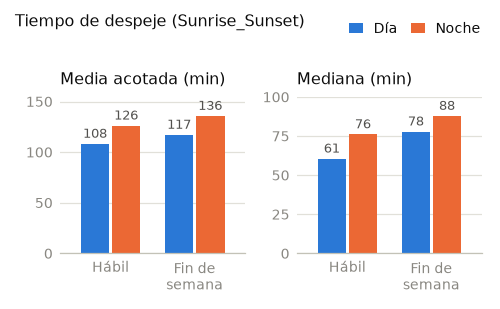

In [18]:
_d = C10[C10["indicador"] == "Sunrise_Sunset"]
fig, ejes = plt.subplots(1, 2, figsize=(3.25, 2.0))
_x, _ancho = np.arange(2), 0.34
for ax, columna, titulo in zip(ejes, ["dur_media_acotada_min", "dur_mediana_min"],
                               ["Media acotada (min)", "Mediana (min)"]):
    for k, (luz, color) in enumerate([("Día", AZUL), ("Noche", NARANJA)]):
        v = _d[_d["luz"] == luz].set_index("tipo_dia")[columna].reindex(["Hábil", "Fin de semana"]).to_numpy()
        pos = _x + (k - 0.5) * (_ancho + 0.03)
        ax.bar(pos, v, width=_ancho, color=color, linewidth=0, label=luz)
        for px, pv in zip(pos, v):
            if np.isfinite(pv):
                ax.annotate(es(pv, 0), (px, pv), xytext=(0, 1.5), textcoords="offset points",
                            ha="center", va="bottom", fontsize=6, color=TINTA_2)
    estilo_ejes(ax)
    ax.set_xticks(_x, ["Hábil", "Fin de\nsemana"])
    ax.set_xlim(-0.6, 1.6)
    ax.margins(y=0.14)
    ax.set_title(titulo, loc="left", color=TINTA)
_marcas, _etiquetas = ejes[0].get_legend_handles_labels()
fig.legend(_marcas, _etiquetas, loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(0.99, 1.0),
           handlelength=1.0, handleheight=0.8, columnspacing=1.0)
fig.suptitle("Tiempo de despeje (Sunrise_Sunset)", x=0.01, y=0.985, ha="left", fontsize=7.5)
fig.tight_layout(rect=(0, 0, 1, 0.95), w_pad=1.2)
guardar_figura(fig, "c10_despeje")

## 9. Segundo escenario: el mismo dataset en Parquet

El CSV obliga a los dos motores a interpretar texto fila por fila en cada consulta, aunque solo usen dos o
tres columnas. **Parquet** es un formato columnar, comprimido y con tipos: guarda cada columna por
separado, así que una consulta lee del disco solo las columnas que necesita y ya no convierte texto en
números o fechas. Es una decisión de almacenamiento, y esta sección mide cuánto pesa en cada tecnología.

**9.1 Conversión.** Se hace una sola vez, con `pyarrow` y por bloques, para no cargar el archivo completo
en memoria. Se aplican los mismos nombres de columnas, los mismos tipos y la misma regla de fechas que en
la lectura del CSV. El tiempo de conversión se informa aparte: es un costo que se paga una vez y se
amortiza en cada consulta posterior.

In [19]:
RUTA_PARQUET = RUTA_PARQUET or os.path.abspath("us_accidents.parquet")
T_CONVERSION = TAMANO_PARQUET_GB = None

if ESCENARIO_PARQUET:
    import pyarrow as pa, pyarrow.csv as pacsv, pyarrow.compute as pc, pyarrow.parquet as pq

    def _tipo_arrow(col):
        if col in COLS_ENTERAS:   return pa.int32()
        if col in COLS_DECIMALES: return pa.float64()
        if col in COLS_BOOLEANAS: return pa.bool_()
        return pa.string()

    def _a_fecha(columna):
        # Misma regla que en la lectura del CSV: primeros 19 caracteres, AAAA-MM-DD HH:MM:SS.
        texto = pc.utf8_slice_codeunits(columna, start=0, stop=19)
        try:
            return pc.cast(texto, pa.timestamp("us"))
        except pa.ArrowInvalid:      # algún valor no es una fecha: se convierte lo posible y el resto queda nulo
            serie = pd.to_datetime(pd.Series(texto.to_pylist(), dtype="object"),
                                   format="%Y-%m-%d %H:%M:%S", errors="coerce")
            return pa.Array.from_pandas(serie, type=pa.timestamp("us"))

    _esquema = pa.schema([(c, pa.timestamp("us") if c in COLS_FECHA else _tipo_arrow(c)) for c in COLUMNAS])
    _lector = pacsv.open_csv(
        RUTA_CSV,
        read_options=pacsv.ReadOptions(block_size=64 << 20),
        convert_options=pacsv.ConvertOptions(column_types={ORIGINAL_DE[c]: _tipo_arrow(c) for c in COLUMNAS},
                                             null_values=[""], strings_can_be_null=True))
    _t0, _filas = time.perf_counter(), 0
    with pq.ParquetWriter(RUTA_PARQUET, _esquema, compression="snappy") as _escritor:
        for _lote in _lector:
            _cols = [_a_fecha(_lote.column(i)) if c in COLS_FECHA else _lote.column(i)
                     for i, c in enumerate(COLUMNAS)]
            _escritor.write_batch(pa.RecordBatch.from_arrays(_cols, schema=_esquema))
            _filas += _lote.num_rows
    T_CONVERSION = time.perf_counter() - _t0
    TAMANO_PARQUET_GB = os.path.getsize(RUTA_PARQUET) / 1e9

    print(f"Conversión: {miles(_filas)} filas en {T_CONVERSION:.0f} s")
    print(f"Tamaño: CSV {es(TAMANO_CSV_GB, 2)} GB → Parquet {es(TAMANO_PARQUET_GB, 2)} GB "
          f"({es(100 * TAMANO_PARQUET_GB / TAMANO_CSV_GB, 0)} % del original)")
    print("Archivo:", RUTA_PARQUET)
else:
    print("Escenario Parquet desactivado (ESCENARIO_PARQUET = False).")

Conversión: 7.728.394 filas en 49 s
Tamaño: CSV 3,06 GB → Parquet 0,78 GB (25 % del original)
Archivo: us_accidents.parquet


**9.2 Control de la conversión.** El Parquet tiene que contener exactamente lo mismo que el CSV: misma
cantidad de filas, mismos nulos en cada columna y mismo rango de fechas.

In [20]:
if ESCENARIO_PARQUET:
    FORMATO = "parquet"
    try:
        _dfp = cargar_spark()
        _ag = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in _dfp.columns]
        _f = _dfp.agg(F.count("*").alias("_n"), F.date_format(F.min("Start_Time"), _FMT).alias("_min"),
                      F.date_format(F.max("Start_Time"), _FMT).alias("_max"), *_ag).first()
    finally:
        FORMATO = "csv"
    _nulos_distintos = [c for c in COLUMNAS if int(_f[c] or 0) != int(NULOS.loc[c, "nulos"])]
    print("Misma cantidad de filas:        ", _f["_n"] == TOTAL_FILAS)
    print("Mismos nulos en las 46 columnas:", not _nulos_distintos,
          "" if not _nulos_distintos else f"(difieren: {_nulos_distintos})")
    print("Mismo rango de fechas:          ", _f["_min"] == FECHA_MIN and _f["_max"] == FECHA_MAX)

Misma cantidad de filas:         True
Mismos nulos en las 46 columnas: True 
Mismo rango de fechas:           True


**9.3 Las cinco consultas sobre Parquet.** Se ejecutan las mismas funciones de la sección 8, sin cambios;
solo cambia el archivo que leen. Para cada consulta se comprueba que Spark y Pandas coincidan entre sí y
que el resultado sea el mismo que se obtuvo con el CSV.

In [21]:
if ESCENARIO_PARQUET:
    FORMATO = "parquet"
    try:
        for _nombre, (_f_spark, _f_pandas) in CONSULTAS.items():
            _r_s = medir(_nombre, "Spark", _f_spark)
            _r_p = medir(_nombre, "Pandas", _f_pandas)
            RES[("parquet", _nombre)] = _r_s
            print(f"    Spark = Pandas: {mismo_resultado(_r_s, _r_p)} | "
                  f"Parquet = CSV: {mismo_resultado(_r_s, RES[('csv', _nombre)])}")
    finally:
        FORMATO = "csv"

[parquet | Spark ] C1 Distribución horaria:    0.53 s  (promedio de 3: 0.70 s)
[parquet | Pandas] C1 Distribución horaria:    0.33 s  (promedio de 3: 0.36 s)
    Spark = Pandas: True | Parquet = CSV: True
[parquet | Spark ] C4 Hotspots:    6.08 s  (promedio de 3: 6.93 s)
[parquet | Pandas] C4 Hotspots:    3.34 s  (promedio de 3: 3.43 s)
    Spark = Pandas: True | Parquet = CSV: True
[parquet | Spark ] C5 Distancia y duración:    1.86 s  (promedio de 3: 2.43 s)
[parquet | Pandas] C5 Distancia y duración:    1.59 s  (promedio de 3: 1.63 s)
    Spark = Pandas: True | Parquet = CSV: True
[parquet | Spark ] C9 Intersecciones:   57.32 s  (promedio de 3: 57.56 s)
[parquet | Pandas] C9 Intersecciones:   56.09 s  (promedio de 3: 56.19 s)
    Spark = Pandas: True | Parquet = CSV: True
[parquet | Spark ] C10 Despeje día/noche:    2.62 s  (promedio de 3: 3.65 s)
[parquet | Pandas] C10 Despeje día/noche:    5.64 s  (promedio de 3: 5.73 s)
    Spark = Pandas: True | Parquet = CSV: True


## 10. Evaluación experimental de rendimiento

Tablas comparativas de las cinco consultas en los dos escenarios. Un Speedup mayor que 1 indica que Spark
fue más rápido; menor que 1, que lo fue Pandas. La última tabla resume cuánto se acelera cada motor al
pasar de CSV a Parquet.

In [22]:
BENCH = tabla_benchmark("csv")
BENCH.reset_index().to_csv("resultados/benchmark.csv", index=False)
pd.DataFrame(RESULTADOS).to_csv("resultados/benchmark_detalle.csv", index=False)

ENTORNO["Repeticiones por consulta"] = REPETICIONES
with open("resultados/entorno.json", "w", encoding="utf-8") as f:
    json.dump(ENTORNO, f, ensure_ascii=False, indent=2, default=str)

print(f"Entorno: {ENTORNO['CPU']} | {ENTORNO['Núcleos físicos']} núcleos físicos, "
      f"{ENTORNO['Núcleos lógicos']} lógicos | {ENTORNO['RAM instalada (GB)']} GB de RAM | "
      f"mejor tiempo de {REPETICIONES} ejecución(es)")
print("\nEscenario 1: CSV original")
display(BENCH.round(2))

BENCH_PARQUET = BENCH_RESUMEN = None
if ESCENARIO_PARQUET:
    BENCH_PARQUET = tabla_benchmark("parquet")
    BENCH_PARQUET.reset_index().to_csv("resultados/benchmark_parquet.csv", index=False)
    print("Escenario 2: Parquet")
    display(BENCH_PARQUET.round(2))

    BENCH_RESUMEN = pd.DataFrame({
        "CSV: Pandas (s)": BENCH["Pandas (s)"], "CSV: Spark (s)": BENCH["Spark (s)"],
        "CSV: Speedup": BENCH["Speedup"],
        "Parquet: Pandas (s)": BENCH_PARQUET["Pandas (s)"], "Parquet: Spark (s)": BENCH_PARQUET["Spark (s)"],
        "Parquet: Speedup": BENCH_PARQUET["Speedup"],
        "Pandas: CSV / Parquet": BENCH["Pandas (s)"] / BENCH_PARQUET["Pandas (s)"],
        "Spark: CSV / Parquet": BENCH["Spark (s)"] / BENCH_PARQUET["Spark (s)"],
    })
    BENCH_RESUMEN.reset_index().to_csv("resultados/benchmark_resumen.csv", index=False)
    print(f"Resumen de los dos escenarios (conversión a Parquet: {T_CONVERSION:.0f} s, una sola vez)")
    display(BENCH_RESUMEN.round(2))

Entorno: Intel(R) Core(TM) i9-10980HK CPU @ 2.40GHz | 8 núcleos físicos, 16 lógicos | 31.7 GB de RAM | mejor tiempo de 3 ejecución(es)

Escenario 1: CSV original


,Pandas (s),Spark (s),Speedup,"Memoria Pandas, pico (GB)","Memoria Spark, JVM (GB)"
Consulta,,,,,
C1 Distribución horaria,21.26,4.11,5.18,1.27,3.92
C4 Hotspots,22.40,8.86,2.53,1.21,5.36
C5 Distancia y duración,29.63,5.55,5.34,2.33,5.35
C9 Intersecciones,79.77,60.69,1.31,3.12,5.38
C10 Despeje día/noche,34.85,8.32,4.19,3.17,4.81


Escenario 2: Parquet


,Pandas (s),Spark (s),Speedup,"Memoria Pandas, pico (GB)","Memoria Spark, JVM (GB)"
Consulta,,,,,
C1 Distribución horaria,0.33,0.53,0.61,0.89,7.78
C4 Hotspots,3.34,6.08,0.55,1.96,8.22
C5 Distancia y duración,1.59,1.86,0.85,2.56,5.59
C9 Intersecciones,56.09,57.32,0.98,3.69,6.15
C10 Despeje día/noche,5.64,2.62,2.15,3.08,5.65


Resumen de los dos escenarios (conversión a Parquet: 49 s, una sola vez)


,CSV: Pandas (s),CSV: Spark (s),CSV: Speedup,Parquet: Pandas (s),Parquet: Spark (s),Parquet: Speedup,Pandas: CSV / Parquet,Spark: CSV / Parquet
Consulta,,,,,,,,
C1 Distribución horaria,21.26,4.11,5.18,0.33,0.53,0.61,65.30,7.74
C4 Hotspots,22.40,8.86,2.53,3.34,6.08,0.55,6.71,1.46
C5 Distancia y duración,29.63,5.55,5.34,1.59,1.86,0.85,18.62,2.98
C9 Intersecciones,79.77,60.69,1.31,56.09,57.32,0.98,1.42,1.06
C10 Despeje día/noche,34.85,8.32,4.19,5.64,2.62,2.15,6.18,3.17


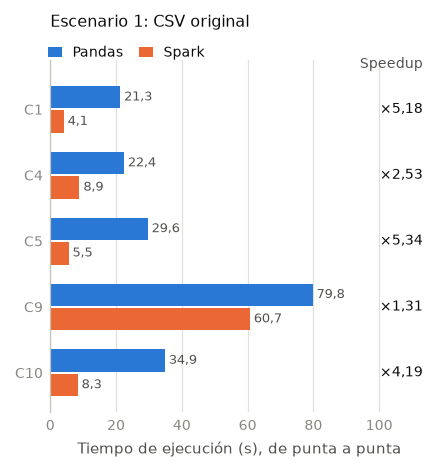

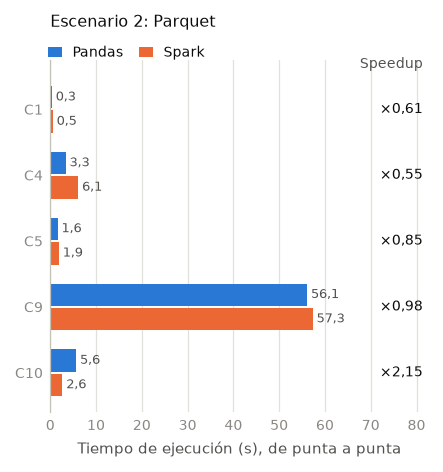

In [23]:
def grafico_benchmark(tabla, archivo, titulo):
    b = tabla.iloc[::-1]                        # la primera consulta queda arriba
    y, alto = np.arange(len(b)), 0.34
    fig, ax = plt.subplots(figsize=(3.25, 0.42 * len(b) + 0.95))
    ax.barh(y + (alto + 0.03) / 2, b["Pandas (s)"], height=alto, color=AZUL, linewidth=0, label="Pandas")
    ax.barh(y - (alto + 0.03) / 2, b["Spark (s)"], height=alto, color=NARANJA, linewidth=0, label="Spark")
    maximo = np.nanmax(b[["Pandas (s)", "Spark (s)"]].to_numpy())
    for yi, (tp, ts, sp) in enumerate(zip(b["Pandas (s)"], b["Spark (s)"], b["Speedup"])):
        ax.text(tp + maximo * 0.015, yi + (alto + 0.03) / 2, es(tp), va="center", fontsize=6, color=TINTA_2)
        ax.text(ts + maximo * 0.015, yi - (alto + 0.03) / 2, es(ts), va="center", fontsize=6, color=TINTA_2)
        ax.text(maximo * 1.42, yi, "×" + es(sp, 2), va="center", ha="right", fontsize=6.5, color=TINTA)
    ax.text(maximo * 1.42, len(b) - 0.42, "Speedup", va="bottom", ha="right", fontsize=6.5, color=TINTA_2)
    estilo_ejes(ax, grilla="x")
    ax.spines["left"].set_color(EJE)
    ax.set_yticks(y, [c.split(" ", 1)[0] for c in b.index])
    ax.set_xlim(0, maximo * 1.44)
    ax.set_ylim(-0.6, len(b) - 0.25)
    ax.set_xlabel("Tiempo de ejecución (s), de punta a punta")
    ax.set_title(titulo, loc="left", color=TINTA, pad=16)
    ax.legend(loc="lower left", bbox_to_anchor=(-0.02, 0.985), ncol=2, frameon=False,
              handlelength=1.0, handleheight=0.8, columnspacing=1.2, borderaxespad=0)
    guardar_figura(fig, archivo)

grafico_benchmark(BENCH, "benchmark_tiempos", "Escenario 1: CSV original")
if ESCENARIO_PARQUET:
    grafico_benchmark(BENCH_PARQUET, "benchmark_tiempos_parquet", "Escenario 2: Parquet")

## 11. Memoria en Pandas

Pandas carga en RAM todo lo que lee. Antes de intentarlo con el archivo completo conviene estimar cuánto ocupa:
se leen las primeras 200.000 filas, se mide la memoria por columna y se extrapola al total.
Las columnas de texto son las que más pesan.

In [24]:
FILAS_MUESTRA = 200_000
_muestra = pd.read_csv(RUTA_CSV, nrows=FILAS_MUESTRA)
_factor = TOTAL_FILAS / len(_muestra)

MEM_COLUMNAS = (_muestra.memory_usage(deep=True).drop("Index") * _factor / 2**30).sort_values(ascending=False)
MEM_ESTIMADA_GB = float(MEM_COLUMNAS.sum())
_disponible = psutil.virtual_memory().available / 2**30

print(f"pandas {pd.__version__} | tipo de las columnas de texto: {_muestra['Description'].dtype}")
print(f"Tamaño del CSV en disco:            {TAMANO_CSV_GB:6.2f} GB")
print(f"Memoria estimada del DataFrame:     {MEM_ESTIMADA_GB:6.2f} GB")
print(f"RAM instalada / disponible ahora:   {RAM_TOTAL_GB:6.2f} GB / {_disponible:.2f} GB")
print("\nLas 8 columnas que más memoria ocupan (GB estimados):")
print(MEM_COLUMNAS.head(8).round(2).to_string())
MEM_COLUMNAS.rename("gb_estimados").rename_axis("columna").reset_index().to_csv(
    "resultados/memoria_pandas_estimada.csv", index=False)
del _muestra

pandas 3.0.6 | tipo de las columnas de texto: str
Tamaño del CSV en disco:              3.06 GB
Memoria estimada del DataFrame:       3.55 GB
RAM instalada / disponible ahora:    31.73 GB / 7.08 GB

Las 8 columnas que más memoria ocupan (GB estimados):
Description          0.53
End_Time             0.19
Start_Time           0.19
Weather_Timestamp    0.19
Street               0.14
Timezone             0.13
City                 0.12
County               0.12


## 12. Descarga de resultados

Todas las tablas quedan en la carpeta `resultados/` y los gráficos en `figuras/` (PNG a 300 ppp, del ancho
de una columna del artículo). Esta celda los comprime en un solo archivo y, en Colab, lo descarga.

In [25]:
RESUMEN = {
    "Archivo": os.path.basename(RUTA_CSV),
    "Tamaño en disco (GB)": round(TAMANO_CSV_GB, 2),
    "Filas": TOTAL_FILAS,
    "Columnas": len(COLUMNAS),
    "Rango de fechas": f"{FECHA_MIN} a {FECHA_MAX}",
    "Estados": int(PERFIL["State"].nunique()),
    "Memoria estimada en Pandas, archivo completo (GB)": round(MEM_ESTIMADA_GB, 1),
    "Parquet: tamaño (GB)": round(TAMANO_PARQUET_GB, 2) if TAMANO_PARQUET_GB else None,
    "Parquet: tiempo de conversión (s)": round(T_CONVERSION, 1) if T_CONVERSION else None,
}
with open("resultados/dataset.json", "w", encoding="utf-8") as f:
    json.dump(RESUMEN, f, ensure_ascii=False, indent=2, default=str)

_zip = "entregables_grupo3"
if os.path.exists(_zip):
    shutil.rmtree(_zip)
os.makedirs(_zip)
shutil.copytree("resultados", os.path.join(_zip, "resultados"))
shutil.copytree("figuras", os.path.join(_zip, "figuras"))
shutil.make_archive(_zip, "zip", _zip)
shutil.rmtree(_zip)
print("Archivo generado:", _zip + ".zip")
print("Contenido:", sorted(os.listdir("resultados")) + sorted(os.listdir("figuras")))

if EN_COLAB and DESCARGAR_ZIP:
    try:
        from google.colab import files
        files.download(_zip + ".zip")
    except Exception as e:
        print("No se pudo iniciar la descarga automática; bajalo desde el panel de archivos.", e)

Archivo generado: entregables_grupo3.zip
Contenido: ['benchmark.csv', 'benchmark_detalle.csv', 'benchmark_parquet.csv', 'benchmark_resumen.csv', 'c10_despeje.csv', 'c1_distribucion_horaria.csv', 'c4_hotspots.csv', 'c5_distancia_duracion.csv', 'c9_categorias.csv', 'c9_cruces_con_ruta.csv', 'c9_intersecciones.csv', 'c9_patrones_enunciado.csv', 'c9_top30_cruces_con_ruta.csv', 'c9_top30_esquinas.csv', 'consigna6_distribucion_clases.csv', 'consigna6_importancia_variables.csv', 'consigna6_matriz_confusion.csv', 'consigna6_metricas.csv', 'dataset.json', 'entorno.json', 'memoria_pandas_estimada.csv', 'perfil_anio.csv', 'perfil_estado.csv', 'perfil_nulos.csv', 'perfil_severidad.csv', 'tiempos_consultas_spark_pandas.csv', 'benchmark_tiempos.png', 'benchmark_tiempos_parquet.png', 'c10_despeje.png', 'c1_distribucion_horaria.png', 'consigna6_distribucion_clases.png', 'consigna6_importancia_variables.png', 'consigna6_matriz_confusion.png', 'consigna6_metricas.png']


## 13. Experimento opcional: cargar el archivo completo en Pandas

El enunciado pide que, si Pandas agota la memoria, se documente el punto de fallo, el tamaño del objeto y
el comportamiento del sistema. Esta celda lo hace de forma controlada:

- Detiene Spark para que Pandas disponga de toda la RAM.
- Lee el archivo en bloques de 500.000 filas y, después de cada uno, muestra y guarda en
  `oom_pandas_log.csv` las filas acumuladas y la memoria usada.
- Si la sesión se cae, la última línea mostrada es el punto de fallo. El archivo de registro sobrevive
  al reinicio de la sesión.

Para ejecutarlo, poné `INTENTAR_CARGA_COMPLETA_PANDAS = True` en la primera celda y corré todo de nuevo.
Como detiene Spark, es siempre el último paso.

In [26]:
if not INTENTAR_CARGA_COMPLETA_PANDAS:
    print("Experimento omitido (INTENTAR_CARGA_COMPLETA_PANDAS = False).")
else:
    spark.stop()
    gc.collect()
    _proceso = psutil.Process()
    _log = "oom_pandas_log.csv"
    with open(_log, "w") as f:
        f.write("filas,segundos,rss_gb,ram_disponible_gb\n")

    _partes, _filas, _t0 = [], 0, time.perf_counter()
    for _bloque in pd.read_csv(RUTA_CSV, chunksize=500_000):
        _partes.append(_bloque)
        _filas += len(_bloque)
        _linea = (f"{_filas},{time.perf_counter() - _t0:.1f},"
                  f"{_proceso.memory_info().rss / 2**30:.2f},"
                  f"{psutil.virtual_memory().available / 2**30:.2f}")
        with open(_log, "a") as f:
            f.write(_linea + "\n")
        print("filas, segundos, RSS GB, RAM disponible GB →", _linea, flush=True)

    print("Bloques leídos. Uniendo en un único DataFrame...", flush=True)
    pdf_completo = pd.concat(_partes, ignore_index=True)
    del _partes
    gc.collect()
    print(f"Carga completa: {len(pdf_completo):,} filas en {time.perf_counter() - _t0:.0f} s | "
          f"DataFrame: {pdf_completo.memory_usage(deep=True).sum() / 2**30:.2f} GB | "
          f"proceso: {_proceso.memory_info().rss / 2**30:.2f} GB")

Experimento omitido (INTENTAR_CARGA_COMPLETA_PANDAS = False).


## 14. Consigna 6: clasificación supervisada con Spark MLlib

### 14.1 Problema, motivación e hipótesis

Se plantea predecir si un siniestro tendrá **severidad alta** (`Severity >= 3`, clases 3 y 4) o **normal** (`Severity < 3`, clases 1 y 2). La detección temprana de eventos de alto impacto potencial puede ayudar a priorizar recursos y comunicar riesgos.

**Hipótesis:** las condiciones meteorológicas, el momento del día y la infraestructura vial aportan información para distinguir ambas clases. Es una hipótesis predictiva, no causal; se medirá sobre las filas efectivamente utilizadas.

`Severity` se usa solo para construir la etiqueta y se excluye de las características. También se excluye `End_Time`, que ocurre después del inicio. La validación aleatoria 80/20 es una primera estimación; una separación temporal sería más estricta para estimar desempeño futuro.

### 14.2 Recorrido

1. Librerías y variables; 2. preparación y balance de clases; 3. train/test; 4. pipeline distribuido; 5. entrenamiento; 6. métricas, gráficos e interpretación.

> Dejar `INTENTAR_CARGA_COMPLETA_PANDAS = False`: el experimento opcional de memoria detiene Spark.

### 14.3 Librerías y variables del modelo

Se separan variables numéricas y categóricas. La etiqueta positiva (1) representa severidad alta.

In [27]:
if INTENTAR_CARGA_COMPLETA_PANDAS:
    raise RuntimeError("Desactiva INTENTAR_CARGA_COMPLETA_PANDAS para ejecutar Consigna 6: esa prueba detiene Spark.")

from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, StringIndexer, VectorAssembler
import matplotlib.pyplot as plt
import zipfile

ML_NUMERICAS = ["Temperature_F", "Humidity_pct", "Pressure_in", "Visibility_mi", "Wind_Speed_mph", "Precipitation_in"]
ML_CATEGORICAS = ["State", "Sunrise_Sunset", "Weather_Condition", "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal"]
ML_TIEMPO = ["hora_inicio", "dia_semana", "mes"]
ML_REQUERIDAS = list(dict.fromkeys(["Severity", "Start_Time"] + ML_NUMERICAS + ML_CATEGORICAS))

### 14.4 Carga y preparación

Se construye la etiqueta, se extraen hora/día/mes de `Start_Time` y se estandarizan los nulos categóricos. El DataFrame se persiste para reutilizarlo en el flujo distribuido.

In [28]:
ML_FORMATO = "parquet" if ESCENARIO_PARQUET and os.path.exists(RUTA_PARQUET) else "csv"
_ML_FORMATO_ANTERIOR = FORMATO
try:
    FORMATO = ML_FORMATO
    ML_BRUTO = cargar_spark()
finally:
    FORMATO = _ML_FORMATO_ANTERIOR

ML_FALTANTES = sorted(set(ML_REQUERIDAS) - set(ML_BRUTO.columns))
if ML_FALTANTES:
    raise ValueError(f"Faltan columnas requeridas para Consigna 6: {ML_FALTANTES}")
ML_DATOS = (
    ML_BRUTO.select(*ML_REQUERIDAS)
    .where(F.col("Severity").between(1, 4))
    .withColumn("label", (F.col("Severity") >= 3).cast("double"))
    .withColumn("_start_ts", F.to_timestamp("Start_Time"))
    .withColumn("hora_inicio", F.hour("_start_ts").cast("double"))
    .withColumn("dia_semana", F.dayofweek("_start_ts").cast("double"))
    .withColumn("mes", F.month("_start_ts").cast("double"))
    .drop("Severity", "Start_Time", "_start_ts")
)
for _col in ML_NUMERICAS + ML_TIEMPO:
    ML_DATOS = ML_DATOS.withColumn(_col, F.col(_col).cast("double"))
for _col in ML_CATEGORICAS:
    ML_DATOS = ML_DATOS.withColumn(_col, F.coalesce(F.col(_col).cast("string"), F.lit("Desconocido")))
ML_DATOS = ML_DATOS.persist(StorageLevel.MEMORY_AND_DISK)
print(f"Fuente: {ML_FORMATO} | filas válidas: {ML_DATOS.count():,}")

Fuente: parquet | filas válidas: 7,728,394


### 14.5 Distribución de clases

La proporción del conjunto efectivo permite contextualizar el desbalance y las métricas.

.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,clase,count
0,Normal (1-2),6224347
1,Alta (3-4),1504047


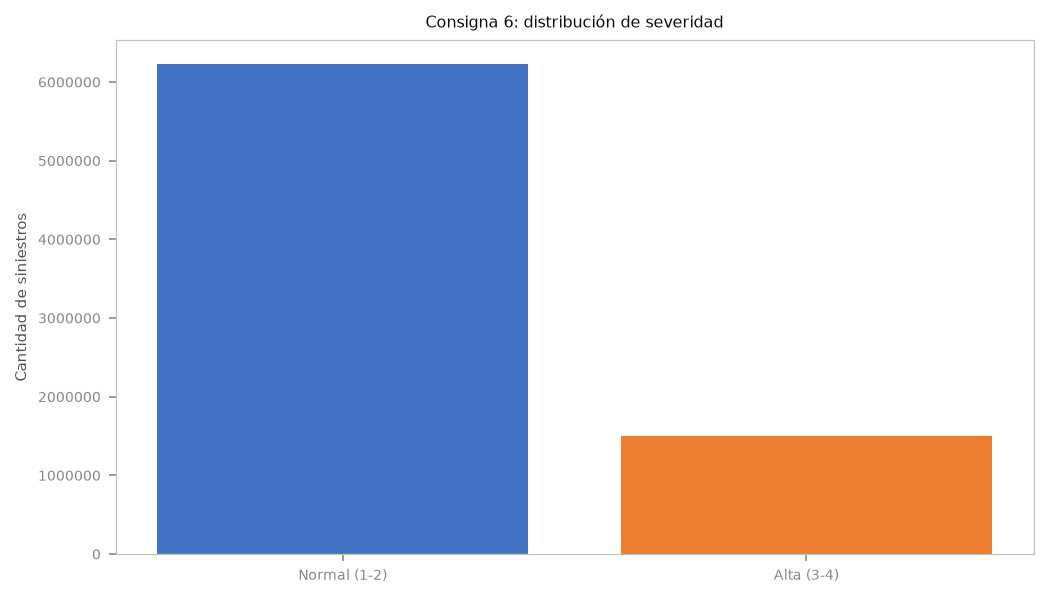

In [29]:
ML_DISTRIBUCION_CLASES = ML_DATOS.groupBy("label").count().orderBy("label")
ML_DISTRIBUCION_PANDAS = ML_DISTRIBUCION_CLASES.toPandas()
ML_DISTRIBUCION_PANDAS["clase"] = ML_DISTRIBUCION_PANDAS["label"].map({0.0: "Normal (1-2)", 1.0: "Alta (3-4)"})
display(ML_DISTRIBUCION_PANDAS[["clase", "count"]])
_fig, _ax = plt.subplots(figsize=(7, 4))
_ax.bar(ML_DISTRIBUCION_PANDAS["clase"], ML_DISTRIBUCION_PANDAS["count"], color=["#4472C4" if label == 0 else "#ED7D31" for label in ML_DISTRIBUCION_PANDAS["label"]])
_ax.set(title="Consigna 6: distribución de severidad", ylabel="Cantidad de siniestros")
_ax.ticklabel_format(axis="y", style="plain")
_fig.tight_layout()
_fig.savefig("figuras/consigna6_distribucion_clases.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(_fig)

### 14.6 Partición train/test

Se separa aleatoriamente 80/20 con semilla fija. Se exige que ambas clases estén presentes en entrenamiento y prueba para que el ajuste y las métricas binarias sean válidos.

**Desbalance de clases.** Cerca de uno de cada cinco siniestros es de severidad alta. Sin corregirlo, el bosque aleatorio predice siempre la clase mayoritaria (exactitud 0,805 igual a la línea de base, recall 0). Por eso cada fila de entrenamiento lleva un peso inversamente proporcional a la frecuencia de su clase (`weightCol`), calculado solo con el conjunto de entrenamiento.

In [30]:
ML_ENTRENAMIENTO, ML_PRUEBA = ML_DATOS.randomSplit([0.8, 0.2], seed=42)
ML_ENTRENAMIENTO = ML_ENTRENAMIENTO.persist(StorageLevel.MEMORY_AND_DISK)
ML_PRUEBA = ML_PRUEBA.persist(StorageLevel.MEMORY_AND_DISK)
ML_FILAS_ENTRENAMIENTO, ML_FILAS_PRUEBA = ML_ENTRENAMIENTO.count(), ML_PRUEBA.count()
if not ML_FILAS_ENTRENAMIENTO or not ML_FILAS_PRUEBA:
    raise RuntimeError("La partición train/test quedó vacía; verifique el dataset.")
ML_CLASES_TRAIN = {float(r["label"]) for r in ML_ENTRENAMIENTO.select("label").distinct().collect()}
ML_CLASES_TEST = {float(r["label"]) for r in ML_PRUEBA.select("label").distinct().collect()}
if ML_CLASES_TRAIN != {0.0, 1.0} or ML_CLASES_TEST != {0.0, 1.0}:
    raise RuntimeError("Train y test deben contener ambas clases para la clasificación binaria.")
ML_TASA_POSITIVA_TEST = float(ML_PRUEBA.agg(F.avg("label")).first()[0])
ML_BASELINE_ACCURACY = max(ML_TASA_POSITIVA_TEST, 1 - ML_TASA_POSITIVA_TEST)
ML_BASELINE_F1_POSITIVA = 2 * ML_TASA_POSITIVA_TEST / (1 + ML_TASA_POSITIVA_TEST)
print(f"Train: {ML_FILAS_ENTRENAMIENTO:,} | Test: {ML_FILAS_PRUEBA:,}")
print(f"Severidad alta en test: {ML_TASA_POSITIVA_TEST:.1%} | baseline accuracy mayoritaria: {ML_BASELINE_ACCURACY:.1%}")

# Pesos de clase: cada clase aporta lo mismo al entrenamiento (se calculan solo con train).
_ML_POSITIVOS_TRAIN = ML_ENTRENAMIENTO.where(F.col("label") == 1).count()
ML_PESO_ALTA = ML_FILAS_ENTRENAMIENTO / (2 * _ML_POSITIVOS_TRAIN)
ML_PESO_NORMAL = ML_FILAS_ENTRENAMIENTO / (2 * (ML_FILAS_ENTRENAMIENTO - _ML_POSITIVOS_TRAIN))
ML_ENTRENAMIENTO = ML_ENTRENAMIENTO.withColumn(
    "peso", F.when(F.col("label") == 1, F.lit(ML_PESO_ALTA)).otherwise(F.lit(ML_PESO_NORMAL)))
print(f"Pesos de clase: normal {ML_PESO_NORMAL:.3f} | alta {ML_PESO_ALTA:.3f}")

Train: 6,183,503 | Test: 1,544,891
Severidad alta en test: 19.5% | baseline accuracy mayoritaria: 80.5%
Pesos de clase: normal 0.621 | alta 2.569


### 14.7 Pipeline de ingeniería de características

La imputación y el indexado se ajustan dentro del pipeline, solo con train; se evita así estimar transformaciones usando el conjunto de prueba. Los árboles no requieren escalado.

In [31]:
ML_NUMERICAS_IMPUTADAS = [f"{c}_imputada" for c in ML_NUMERICAS + ML_TIEMPO]
ML_CATEGORICAS_INDEXADAS = [f"{c}_idx" for c in ML_CATEGORICAS]
ML_CATEGORICAS_OHE = [f"{c}_ohe" for c in ML_CATEGORICAS]
ML_IMPUTER = Imputer(strategy="median", inputCols=ML_NUMERICAS + ML_TIEMPO, outputCols=ML_NUMERICAS_IMPUTADAS)
ML_INDEXERS = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in ML_CATEGORICAS]
ML_ENCODER = OneHotEncoder(inputCols=ML_CATEGORICAS_INDEXADAS, outputCols=ML_CATEGORICAS_OHE, handleInvalid="keep")
ML_ASSEMBLER = VectorAssembler(inputCols=ML_NUMERICAS_IMPUTADAS + ML_CATEGORICAS_OHE, outputCol="features", handleInvalid="keep")
ML_CLASIFICADOR = RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="peso", numTrees=60, maxDepth=8, minInstancesPerNode=10, seed=42, featureSubsetStrategy="sqrt")
ML_PIPELINE = Pipeline(stages=[ML_IMPUTER] + ML_INDEXERS + [ML_ENCODER, ML_ASSEMBLER, ML_CLASIFICADOR])
print("Imputer → StringIndexer → OneHotEncoder → VectorAssembler → RandomForestClassifier")

Imputer → StringIndexer → OneHotEncoder → VectorAssembler → RandomForestClassifier


### 14.8 Entrenamiento y predicción

Se ajusta el pipeline con train y se generan predicciones para las filas reservadas de test.

In [32]:
ML_MODELO = ML_PIPELINE.fit(ML_ENTRENAMIENTO)
ML_PREDICCIONES = ML_MODELO.transform(ML_PRUEBA).persist(StorageLevel.MEMORY_AND_DISK)
ML_FILAS_PREDICHAS = ML_PREDICCIONES.count()
print(f"Modelo entrenado; predicciones materializadas para {ML_FILAS_PREDICHAS:,} filas de prueba.")

Modelo entrenado; predicciones materializadas para 1,544,891 filas de prueba.


### 14.9 Métricas y matriz de confusión

Se calculan ROC-AUC, PR-AUC, F1, precisión y recall para severidad alta, y accuracy. PR-AUC y las métricas de la clase positiva ayudan a no ocultar errores por desbalance.

In [33]:
ML_EVALUADOR_ROC = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
ML_EVALUADOR_PR = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
ML_EVALUADOR_F1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="fMeasureByLabel", metricLabel=1.0)
ML_EVALUADOR_PRECISION = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0)
ML_EVALUADOR_RECALL = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0)
ML_EVALUADOR_ACCURACY = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
ML_RESULTADOS = {
    "roc_auc": ML_EVALUADOR_ROC.evaluate(ML_PREDICCIONES),
    "pr_auc": ML_EVALUADOR_PR.evaluate(ML_PREDICCIONES),
    "f1_severidad_alta": ML_EVALUADOR_F1.evaluate(ML_PREDICCIONES),
    "precision_severidad_alta": ML_EVALUADOR_PRECISION.evaluate(ML_PREDICCIONES),
    "recall_severidad_alta": ML_EVALUADOR_RECALL.evaluate(ML_PREDICCIONES),
    "accuracy": ML_EVALUADOR_ACCURACY.evaluate(ML_PREDICCIONES),
    "accuracy_baseline_mayoritaria": ML_BASELINE_ACCURACY,
    "f1_baseline_siempre_positivo": ML_BASELINE_F1_POSITIVA,
    "proporcion_severidad_alta_test": ML_TASA_POSITIVA_TEST,
    "filas_train": ML_FILAS_ENTRENAMIENTO, "filas_test": ML_FILAS_PRUEBA,
    "modelo": "RandomForestClassifier (60 árboles, profundidad 8, pesos de clase)", "semilla": 42,
}
ML_METRICAS = pd.DataFrame([ML_RESULTADOS])
display(ML_METRICAS.round(4))
ML_MATRIZ_CONFUSION = ML_PREDICCIONES.groupBy("label", "prediction").count().orderBy("label", "prediction")
print("Matriz de confusión (filas = clase real; columnas = predicha):")
ML_MATRIZ_CONFUSION.show()

,roc_auc,pr_auc,f1_severidad_alta,precision_severidad_alta,recall_severidad_alta,accuracy,accuracy_baseline_mayoritaria,f1_baseline_siempre_positivo,proporcion_severidad_alta_test,filas_train,filas_test,modelo,semilla
0,0.7235,0.3825,0.4321,0.3134,0.6959,0.6441,0.8054,0.3258,0.1946,6183503,1544891,"RandomForestClassifier (60 árboles, profundidad 8, pesos de clase)",42


Matriz de confusión (filas = clase real; columnas = predicha):
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|  0.0|       0.0|785772|
|  0.0|       1.0|458461|
|  1.0|       0.0| 91441|
|  1.0|       1.0|209217|
+-----+----------+------+



### 14.10 Gráficos de métricas y errores

El gráfico compara métricas en escala 0–1 y muestra referencias simples. La matriz de confusión ayuda a localizar siniestros graves no detectados (falsos negativos) y falsas alarmas.

.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


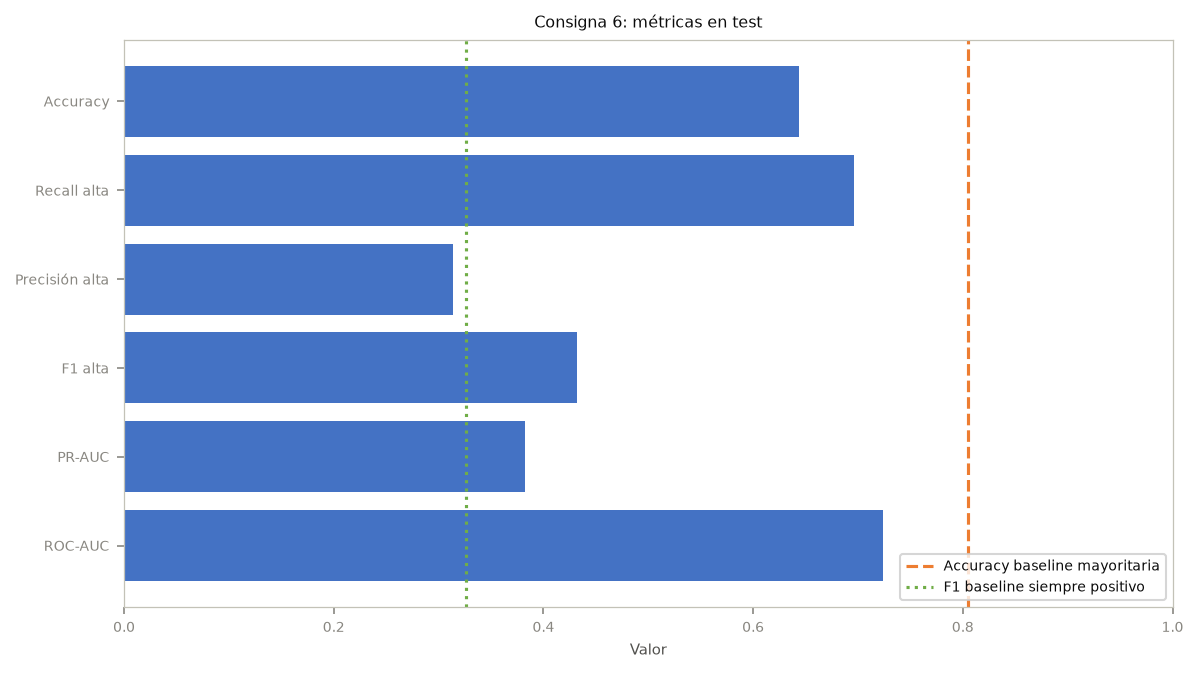

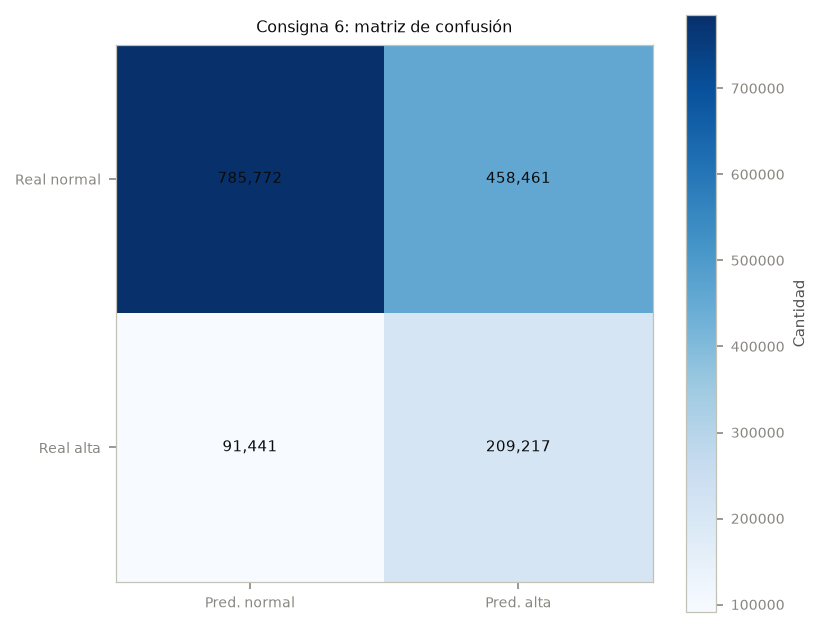

In [34]:
ML_CM_PANDAS = ML_MATRIZ_CONFUSION.toPandas()
ML_CM_PIVOT = ML_CM_PANDAS.pivot(index="label", columns="prediction", values="count").reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0).fillna(0)
ML_METRICAS_GRAFICO = [("ROC-AUC", ML_RESULTADOS["roc_auc"]), ("PR-AUC", ML_RESULTADOS["pr_auc"]), ("F1 alta", ML_RESULTADOS["f1_severidad_alta"]), ("Precisión alta", ML_RESULTADOS["precision_severidad_alta"]), ("Recall alta", ML_RESULTADOS["recall_severidad_alta"]), ("Accuracy", ML_RESULTADOS["accuracy"])]
_fig, _ax = plt.subplots(figsize=(8, 4.5))
_ax.barh([x[0] for x in ML_METRICAS_GRAFICO], [x[1] for x in ML_METRICAS_GRAFICO], color="#4472C4")
_ax.axvline(ML_BASELINE_ACCURACY, color="#ED7D31", linestyle="--", label="Accuracy baseline mayoritaria")
_ax.axvline(ML_BASELINE_F1_POSITIVA, color="#70AD47", linestyle=":", label="F1 baseline siempre positivo")
_ax.set_xlim(0, 1); _ax.set_xlabel("Valor"); _ax.set_title("Consigna 6: métricas en test"); _ax.legend(loc="lower right")
_fig.tight_layout(); _fig.savefig("figuras/consigna6_metricas.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(_fig)

_fig, _ax = plt.subplots(figsize=(5.5, 4.5))
_im = _ax.imshow(ML_CM_PIVOT.to_numpy(), cmap="Blues")
_ax.set_xticks([0, 1], ["Pred. normal", "Pred. alta"]); _ax.set_yticks([0, 1], ["Real normal", "Real alta"])
_ax.set_title("Consigna 6: matriz de confusión")
for _i in range(2):
    for _j in range(2): _ax.text(_j, _i, f"{int(ML_CM_PIVOT.iloc[_i, _j]):,}", ha="center", va="center")
_fig.colorbar(_im, ax=_ax, label="Cantidad"); _fig.tight_layout()
_fig.savefig("figuras/consigna6_matriz_confusion.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(_fig)

### 14.11 Importancia de variables

La importancia del Random Forest resume la contribución predictiva de cada característica para este modelo; no indica si aumenta o reduce la probabilidad ni prueba causalidad.

,variable,importancia
0,Weather_Condition_ohe_Fair,0.141354
1,Crossing_ohe_false,0.127051
2,Traffic_Signal_ohe_true,0.080721
3,Weather_Condition_ohe_Clear,0.074161
4,Crossing_ohe_true,0.068374
5,Traffic_Signal_ohe_false,0.059208
6,Pressure_in_imputada,0.051707
7,Wind_Speed_mph_imputada,0.043558
8,Weather_Condition_ohe_Overcast,0.033718
9,State_ohe_IL,0.028685


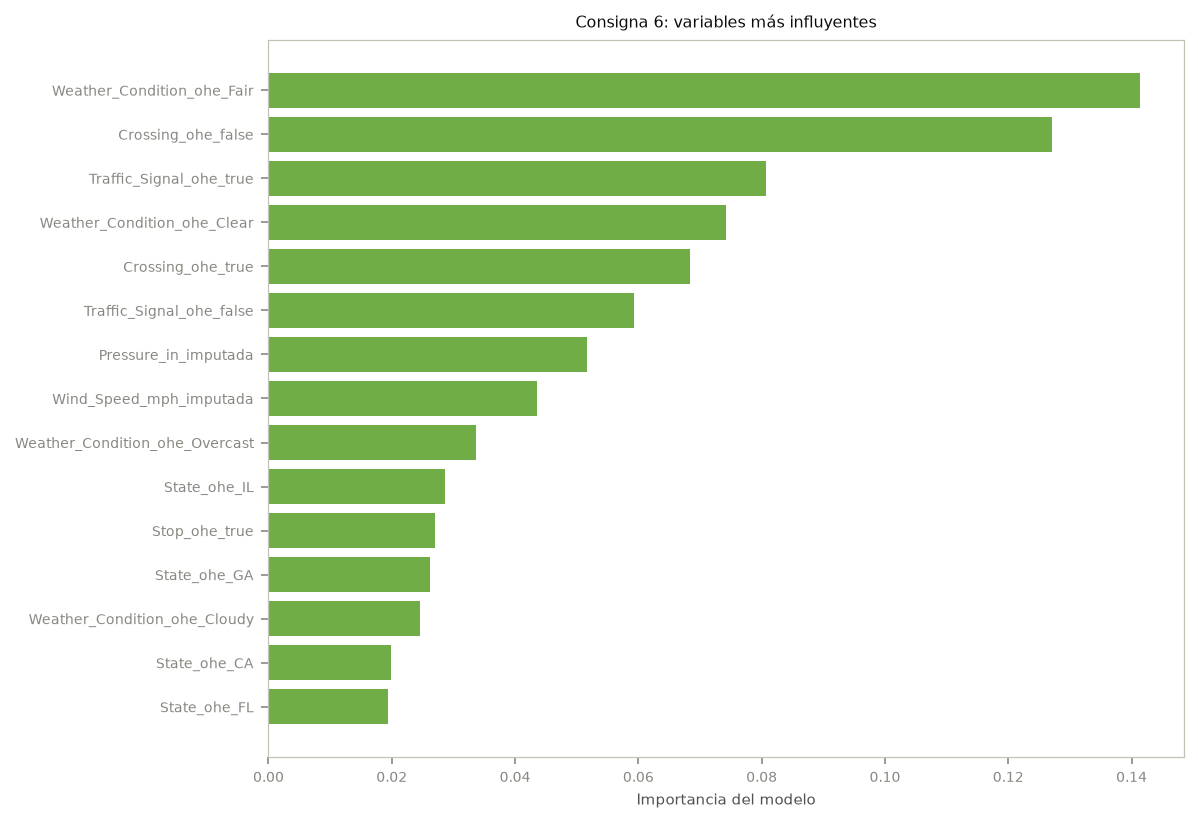

In [35]:
ML_IMPORTANCIAS_VECTOR = ML_MODELO.stages[-1].featureImportances.toArray()
ML_ATRIBUTOS = ML_PREDICCIONES.schema["features"].metadata.get("ml_attr", {}).get("attrs", {})
ML_NOMBRES_ATRIBUTOS = {}
for _grupo in ML_ATRIBUTOS.values():
    for _atributo in _grupo:
        ML_NOMBRES_ATRIBUTOS[int(_atributo["idx"])] = _atributo.get("name", f"feature_{_atributo['idx']}")
ML_IMPORTANCIAS = pd.DataFrame({"variable": [ML_NOMBRES_ATRIBUTOS.get(i, f"feature_{i}") for i in range(len(ML_IMPORTANCIAS_VECTOR))], "importancia": ML_IMPORTANCIAS_VECTOR}).sort_values("importancia", ascending=False)
ML_TOP_IMPORTANCIAS = ML_IMPORTANCIAS.head(15).sort_values("importancia")
display(ML_IMPORTANCIAS.head(10).reset_index(drop=True))
_fig, _ax = plt.subplots(figsize=(8, 5.5))
_ax.barh(ML_TOP_IMPORTANCIAS["variable"], ML_TOP_IMPORTANCIAS["importancia"], color="#70AD47")
_ax.set(xlabel="Importancia del modelo", title="Consigna 6: variables más influyentes")
_fig.tight_layout(); _fig.savefig("figuras/consigna6_importancia_variables.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(_fig)

### 14.12 Interpretación y contraste con la hipótesis

La lectura siguiente compara el modelo con referencias simples. Además de ROC-AUC y PR-AUC, importan el recall de severidad alta y los falsos negativos. Los resultados del split aleatorio no establecen causalidad ni dirección de los efectos.

In [36]:
print(f"ROC-AUC = {ML_RESULTADOS['roc_auc']:.3f}: ", end="")
print("mejor ordenamiento que azar en este test." if ML_RESULTADOS["roc_auc"] > 0.5 else "no supera la referencia aleatoria 0.5.")
print(f"PR-AUC = {ML_RESULTADOS['pr_auc']:.3f}; prevalencia positiva = {ML_TASA_POSITIVA_TEST:.3f}: ", end="")
print("supera la referencia de prevalencia." if ML_RESULTADOS["pr_auc"] > ML_TASA_POSITIVA_TEST else "no supera la referencia de prevalencia.")
print(f"F1 alta = {ML_RESULTADOS['f1_severidad_alta']:.3f} (baseline siempre positivo = {ML_BASELINE_F1_POSITIVA:.3f}); recall alta = {ML_RESULTADOS['recall_severidad_alta']:.3f}.")
print(f"Accuracy = {ML_RESULTADOS['accuracy']:.3f} (baseline mayoritaria = {ML_BASELINE_ACCURACY:.3f}).")
ML_HIPOTESIS_RESPALDADA = ML_RESULTADOS["roc_auc"] > 0.5 and ML_RESULTADOS["pr_auc"] > ML_TASA_POSITIVA_TEST and ML_RESULTADOS["f1_severidad_alta"] > ML_BASELINE_F1_POSITIVA
if ML_HIPOTESIS_RESPALDADA:
    print("Conclusión preliminar: las variables incluidas muestran señal predictiva conjunta para distinguir severidad alta en esta partición.")
else:
    print("Conclusión preliminar: la evidencia es mixta y no supera conjuntamente las referencias predefinidas.")
print("La importancia de variables no prueba causalidad ni permite inferir por sí sola el sentido del efecto.")

ROC-AUC = 0.724: mejor ordenamiento que azar en este test.
PR-AUC = 0.383; prevalencia positiva = 0.195: supera la referencia de prevalencia.
F1 alta = 0.432 (baseline siempre positivo = 0.326); recall alta = 0.696.
Accuracy = 0.644 (baseline mayoritaria = 0.805).
Conclusión preliminar: las variables incluidas muestran señal predictiva conjunta para distinguir severidad alta en esta partición.
La importancia de variables no prueba causalidad ni permite inferir por sí sola el sentido del efecto.


### 14.13 Exportación de resultados

Se guardan métricas, matriz, balance e importancias junto a los gráficos y se actualiza el ZIP de entregables.

In [37]:
os.makedirs("resultados", exist_ok=True)
ML_METRICAS.to_csv("resultados/consigna6_metricas.csv", index=False)
ML_CM_PANDAS.to_csv("resultados/consigna6_matriz_confusion.csv", index=False)
ML_DISTRIBUCION_PANDAS.to_csv("resultados/consigna6_distribucion_clases.csv", index=False)
ML_IMPORTANCIAS.to_csv("resultados/consigna6_importancia_variables.csv", index=False)
with zipfile.ZipFile("entregables_grupo3.zip", "w", compression=zipfile.ZIP_DEFLATED) as _zip_ml:
    for _carpeta in ("resultados", "figuras"):
        for _raiz, _directorios, _archivos in os.walk(_carpeta):
            for _archivo in _archivos:
                _ruta = os.path.join(_raiz, _archivo)
                _zip_ml.write(_ruta, arcname=os.path.relpath(_ruta, "."))
ML_PREDICCIONES.unpersist(); ML_ENTRENAMIENTO.unpersist(); ML_PRUEBA.unpersist(); ML_DATOS.unpersist()
print("Resultados guardados en resultados/, figuras/ y entregables_grupo3.zip.")

Resultados guardados en resultados/, figuras/ y entregables_grupo3.zip.
